install librarys

In [ ]:
%pip install -U ultralytics ultralytics-platform pyyaml geoai-py

Set up project folder

In [ ]:

from pathlib import Path
import shutil
import json
import zipfile
import os

# All project outputs saved locally in Colab
PROJECT_DIR = Path("/content/ship_detection")
RUN_NAME = "dota_v15_ship_tiled_512"
RUN_DIR = PROJECT_DIR / RUN_NAME

# Create folders for outputs
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Training run folder:", RUN_DIR)
print("Google Drive is not required.")


Project folder: /content/ship_detection
Training run folder: /content/ship_detection/dota_v15_ship_tiled_512
Google Drive is not required.


Configure ultralytics

In [ ]:
from google.colab import userdata
import os

os.environ["ULTRALYTICS_API_KEY"] = userdata.get("ULTRALYTICS_API_KEY")

print("Ultralytics API key configured.")

Ultralytics API key configured.


check if gpu available

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU available. Do not start the training cell yet.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU count: 1
GPU: Tesla T4


Import dotav1.5 data

In [ ]:
from google.colab import files

uploaded = files.upload()

ndjson_path = next(
    name for name in uploaded
    if name.lower().endswith(".ndjson")
)

print("NDJSON file:", ndjson_path)

Saving dota_v15_ship_results.zip to dota_v15_ship_results.zip


StopIteration: 

In [ ]:
from ultralytics.data.converter import convert_ndjson_to_yolo

dataset_yaml = await convert_ndjson_to_yolo(
    ndjson_path=ndjson_path,
    output_path="/content/dota_v15",
    fraction=1.0
)

print("Dataset YAML:", dataset_yaml)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Converting dota-v15 (1).ndjson fraction=1.0 → /content/dota_v15/dota-v15 (1)-29f97b52 using 1964 train, 561 val, 281 test images: 100% ━━━━━━━━━━━━ 2806/2806 86.9it/s 32.3s
Dataset YAML: /content/dota_v15/dota-v15 (1)-29f97b52/data.yaml


In [ ]:
from pathlib import Path
import yaml

dataset_yaml = Path(dataset_yaml)

print("YAML exists:", dataset_yaml.exists())

with open(dataset_yaml, "r") as f:
    data_config = yaml.safe_load(f)

print("Classes:", data_config.get("names"))
print("Train:", data_config.get("train"))
print("Validation:", data_config.get("val"))
print("Test:", data_config.get("test"))

YAML exists: True
Classes: {0: 'plane', 1: 'ship', 2: 'storage tank', 3: 'baseball diamond', 4: 'tennis court', 5: 'basketball court', 6: 'ground track field', 7: 'harbor', 8: 'bridge', 9: 'large vehicle', 10: 'small vehicle', 11: 'helicopter', 12: 'roundabout', 13: 'soccer ball field', 14: 'swimming pool', 15: 'container crane'}
Train: images/train
Validation: images/val
Test: images/test


Selecting ship class only (class filtering, OBB label checks)

In [ ]:
from pathlib import Path
import yaml
import shutil

# Locate the converted dataset's image folders
search_root = Path("/content/dota_v15")
image_root = None

for p in search_root.rglob("train"):
    if (
        p.is_dir()
        and p.parent.name == "images"
        and all((p.parent / split).is_dir()
                for split in ["val", "test"])
    ):
        image_root = p.parent
        break

if image_root is None:
    raise FileNotFoundError(
        "Could not find images/train, images/val and images/test "
        "under /content/dota_v15."
    )

source_root = image_root.parent
print("Detected dataset root:", source_root)

# Find the source YAML
yaml_candidates = list(source_root.rglob("*.yaml"))
if not yaml_candidates:
    raise FileNotFoundError("No dataset YAML found.")

source_yaml = Path(dataset_yaml)
if not source_yaml.exists() or source_yaml.suffix.lower() not in {".yaml", ".yml"}:
    source_yaml = yaml_candidates[0]

with open(source_yaml, "r") as f:
    original_config = yaml.safe_load(f)

names = original_config["names"]
if isinstance(names, list):
    names = {i: name for i, name in enumerate(names)}
else:
    names = {int(k): v for k, v in names.items()}

ship_ids = [
    i for i, name in names.items()
    if str(name).strip().lower() == "ship"
]
assert len(ship_ids) == 1, f"Unexpected ship class IDs: {ship_ids}"
ship_id = ship_ids[0]

print("Ship class ID:", ship_id)

# Create a separate ship-only dataset
output_root = Path("/content/dota_v15_ships")

if output_root.exists():
    shutil.rmtree(output_root)

shutil.copytree(source_root, output_root)

# Keep ships and remap their class ID to 0
kept = 0
removed = 0

for label_file in (output_root / "labels").rglob("*.txt"):
    new_lines = []

    for line in label_file.read_text().splitlines():
        parts = line.split()
        if not parts:
            continue

        if int(float(parts[0])) == ship_id:
            parts[0] = "0"
            new_lines.append(" ".join(parts))
            kept += 1
        else:
            removed += 1

    label_file.write_text(
        "\n".join(new_lines) + ("\n" if new_lines else "")
    )

print("Ship annotations retained:", kept)
print("Other annotations removed:", removed)

# Write a clean YAML using the detected folder structure
ship_yaml = output_root / "ships_only.yaml"

ship_config = {
    "path": str(output_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "ship"},
    "nc": 1
}

with open(ship_yaml, "w") as f:
    yaml.safe_dump(ship_config, f, sort_keys=False)

print("\nShip-only YAML:")
print(ship_yaml.read_text())

Detected dataset root: /content/dota_v15/dota-v15 (1)-29f97b52
Ship class ID: 1
Ship annotations retained: 43738
Other annotations removed: 236372

Ship-only YAML:
path: /content/dota_v15_ships
train: images/train
val: images/val
test: images/test
names:
  0: ship
nc: 1



Checking OBB labels

In [ ]:
from pathlib import Path

for split in ["train", "val", "test"]:
    image_dir = output_root / "images" / split
    label_dir = output_root / "labels" / split

    assert image_dir.is_dir(), f"Missing image folder: {image_dir}"
    assert label_dir.is_dir(), f"Missing label folder: {label_dir}"

    images = [
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    ]
    labels = list(label_dir.rglob("*.txt"))

    print(
        f"{split}: {len(images):,} images, "
        f"{len(labels):,} label files"
    )

    assert images, f"No images found in {image_dir}"

# Check that non-empty OBB annotations have 9 values
label_files = list((output_root / "labels" / "train").rglob("*.txt"))
sample_labels = [p for p in label_files if p.stat().st_size > 0]

assert sample_labels, "No non-empty training labels found."

sample = sample_labels[0]
line = sample.read_text().strip().splitlines()[0]
values = line.split()

print("\nSample label:", line)
print("Values per annotation:", len(values))

assert len(values) == 9, (
    "Expected OBB labels with 9 values: class ID and 8 corner coordinates."
)
assert values[0] == "0", "Expected ship class ID 0."

print("Dataset verification passed.")

train: 1,964 images, 1,964 label files
val: 561 images, 561 label files
test: 281 images, 281 label files

Sample label: 0 0.5393 0.44807 0.5393 0.44308 0.5534 0.4428 0.5529 0.44807
Values per annotation: 9
Dataset verification passed.


Create tiled dataset

In [ ]:
from pathlib import Path
from PIL import Image
from shapely.geometry import Polygon, box
import random
import shutil
import yaml

# Existing ship-only dataset
source_root = Path("/content/dota_v15_ships")

# New tiled dataset
tile_root = Path("/content/dota_v15_ships_tiled")

TILE_SIZE = 512
STRIDE = 256
MIN_RETAINED_AREA = 0.50

# Sample 50% of original images containing valid labelled ships
SAMPLE_FRACTION = 0.50
RANDOM_SEED = 42

# Start with a clean output directory
if tile_root.exists():
    shutil.rmtree(tile_root)

for split in ["train", "val", "test"]:
    (tile_root / "images" / split).mkdir(parents=True)
    (tile_root / "labels" / split).mkdir(parents=True)


def tile_starts(length):
    """Generate tile starts with 50% overlap and cover the far edge."""
    if length <= TILE_SIZE:
        return [0]

    starts = list(range(0, length - TILE_SIZE + 1, STRIDE))
    final_start = length - TILE_SIZE

    if starts[-1] != final_start:
        starts.append(final_start)

    return starts


def read_ship_polygons(label_path, image_width, image_height):
    """Read normalized YOLO OBB labels and convert to pixel polygons."""
    polygons = []

    if not label_path.exists():
        return polygons

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) != 9:
            continue

        class_id = int(float(parts[0]))
        coords = [float(v) for v in parts[1:]]

        points = [
            (coords[i] * image_width, coords[i + 1] * image_height)
            for i in range(0, 8, 2)
        ]

        polygon = Polygon(points)

        if polygon.is_valid and polygon.area > 0:
            polygons.append((class_id, polygon))

    return polygons


def labels_for_tile(polygons, left, top, image_width, image_height):
    """Clip ship polygons to the tile and convert to tile coordinates."""
    tile_right = min(left + TILE_SIZE, image_width)
    tile_bottom = min(top + TILE_SIZE, image_height)
    tile_bounds = box(left, top, tile_right, tile_bottom)

    output_lines = []

    for class_id, polygon in polygons:
        clipped = polygon.intersection(tile_bounds)

        if clipped.is_empty or clipped.geom_type != "Polygon":
            continue

        if polygon.area <= 0:
            continue

        retained_fraction = clipped.area / polygon.area

        if retained_fraction < MIN_RETAINED_AREA:
            continue

        # Represent the clipped polygon as an oriented rectangle.
        rect = clipped.minimum_rotated_rectangle

        if rect.geom_type != "Polygon":
            continue

        points = list(rect.exterior.coords)[:4]

        if len(points) != 4:
            continue

        normalized = []

        for x, y in points:
            normalized.extend([
                max(0.0, min(1.0, (x - left) / TILE_SIZE)),
                max(0.0, min(1.0, (y - top) / TILE_SIZE))
            ])

        output_lines.append(
            str(class_id) + " " +
            " ".join(f"{v:.6f}" for v in normalized)
        )

    return output_lines


total_tiles = {"train": 0, "val": 0, "test": 0}
positive_tiles = {"train": 0, "val": 0, "test": 0}
empty_tiles = {"train": 0, "val": 0, "test": 0}
skipped_images = {"train": 0, "val": 0, "test": 0}
sampled_out_images = {"train": 0, "val": 0, "test": 0}

for split in ["train", "val", "test"]:
    image_dir = source_root / "images" / split
    label_dir = source_root / "labels" / split

    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    )

    print(f"\nTiling {split}: {len(image_paths)} source images")

    # First, identify original images containing valid ship labels.
    valid_image_paths = []

    for image_path in image_paths:
        label_path = label_dir / f"{image_path.stem}.txt"

        with Image.open(image_path) as im:
            width, height = im.size

        polygons = read_ship_polygons(label_path, width, height)

        if polygons:
            valid_image_paths.append(image_path)
        else:
            skipped_images[split] += 1

    # Randomly select 50% of valid ship-containing images.
    sample_size = max(
        1,
        round(len(valid_image_paths) * SAMPLE_FRACTION)
    ) if valid_image_paths else 0

    rng = random.Random(
        RANDOM_SEED + ["train", "val", "test"].index(split)
    )

    image_paths = sorted(
        rng.sample(valid_image_paths, sample_size)
    )

    sampled_out_images[split] = (
        len(valid_image_paths) - len(image_paths)
    )

    print(
        f"Original images with valid ship labels: "
        f"{len(valid_image_paths):,}"
    )
    print(
        f"Original images selected for tiling: "
        f"{len(image_paths):,}"
    )
    print(
        f"Valid images not selected: "
        f"{sampled_out_images[split]:,}"
    )

    # Tile each selected image, retaining positive and empty tiles.
    for image_path in image_paths:
        label_path = label_dir / f"{image_path.stem}.txt"

        with Image.open(image_path) as im:
            image = im.convert("RGB")

        width, height = image.size
        polygons = read_ship_polygons(label_path, width, height)

        for top in tile_starts(height):
            for left in tile_starts(width):
                right = min(left + TILE_SIZE, width)
                bottom = min(top + TILE_SIZE, height)

                crop = image.crop((left, top, right, bottom))

                # Pad edge tiles to 512 x 512 when needed.
                if crop.size != (TILE_SIZE, TILE_SIZE):
                    padded = Image.new(
                        "RGB", (TILE_SIZE, TILE_SIZE), (0, 0, 0)
                    )
                    padded.paste(crop, (0, 0))
                    crop = padded

                tile_labels = labels_for_tile(
                    polygons, left, top, width, height
                )

                tile_name = f"{image_path.stem}_x{left}_y{top}.jpg"

                # Save ALL tiles, including those without qualifying labels.
                crop.save(
                    tile_root / "images" / split / tile_name,
                    quality=95
                )

                label_out = (
                    tile_root / "labels" / split /
                    (Path(tile_name).stem + ".txt")
                )

                # Empty label files are intentional negative examples.
                label_out.write_text(
                    "\n".join(tile_labels) +
                    ("\n" if tile_labels else "")
                )

                total_tiles[split] += 1

                if tile_labels:
                    positive_tiles[split] += 1
                else:
                    empty_tiles[split] += 1

    print(
        f"Original images skipped (no valid ship labels): "
        f"{skipped_images[split]:,}"
    )
    print(
        f"Total tiles saved: {total_tiles[split]:,}"
    )
    print(
        f"Tiles containing labelled ships: "
        f"{positive_tiles[split]:,}"
    )
    print(
        f"Empty tiles from selected ship-containing images: "
        f"{empty_tiles[split]:,}"
    )

# Create YAML for the tiled dataset
tiled_yaml = tile_root / "ships_tiled.yaml"

tiled_config = {
    "path": str(tile_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "ship"},
    "nc": 1
}

with open(tiled_yaml, "w") as f:
    yaml.safe_dump(tiled_config, f, sort_keys=False)

print("\nTiled dataset YAML:")
print(tiled_yaml.read_text())

# Dataset checks
for split in ["train", "val", "test"]:
    assert positive_tiles[split] > 0, (
        f"No positive {split} tiles found."
    )
    assert total_tiles[split] == (
        positive_tiles[split] + empty_tiles[split]
    ), f"Tile count mismatch for {split}."

    assert len(list((tile_root / "images" / split).glob("*.jpg"))) == total_tiles[split]

assert (tile_root / "images" / "train").exists()
assert (tile_root / "images" / "val").exists()
assert (tile_root / "images" / "test").exists()

print("Tiling and dataset checks complete.")


Tiling train: 1964 source images
Original images with valid ship labels: 411
Original images selected for tiling: 206
Valid images not selected: 205
Original images skipped (no valid ship labels): 1,553
Total tiles saved: 17,017
Tiles containing labelled ships: 4,758
Empty tiles from selected ship-containing images: 12,259

Tiling val: 561 source images
Original images with valid ship labels: 108
Original images selected for tiling: 54
Valid images not selected: 54
Original images skipped (no valid ship labels): 453
Total tiles saved: 4,144
Tiles containing labelled ships: 1,339
Empty tiles from selected ship-containing images: 2,805

Tiling test: 281 source images
Original images with valid ship labels: 54
Original images selected for tiling: 27
Valid images not selected: 27
Original images skipped (no valid ship labels): 227
Total tiles saved: 1,998
Tiles containing labelled ships: 698
Empty tiles from selected ship-containing images: 1,300

Tiled dataset YAML:
path: /content/dota_v

Train YOLO11s-OBB model

In [ ]:
from ultralytics import YOLO

# Start from pretrained YOLO11 small OBB weights
model = YOLO("yolo11s-obb.pt")

results = model.train(
    data="/content/dota_v15_ships_tiled/ships_tiled.yaml",
    epochs=10,
    patience=5,
    imgsz=512,
    batch=4,
    device=0,
    workers=2,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    save_period=5,
    seed=42
)

print("Training complete.")
print("Training run:", RUN_DIR)
print("Best model:", RUN_DIR / "weights" / "best.pt")
print("Last model:", RUN_DIR / "weights" / "last.pt")
print("Training log:", RUN_DIR / "results.csv")
print("Training plots:", RUN_DIR / "results.png")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dota_v15_ships_tiled/ships_tiled.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-obb.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dota_v15_ship_tiled_512, nbs=64, nms=Non

keep best model

In [ ]:
from ultralytics import YOLO

best_model_path = RUN_DIR / "weights" / "best.pt"

assert best_model_path.exists(), (
    f"Best checkpoint not found: {best_model_path}"
)

best_model = YOLO(str(best_model_path))

print("Best trained model loaded:", best_model_path)

AssertionError: Best checkpoint not found: /content/ship_detection/dota_v15_ship_tiled_512/weights/best.pt

In [ ]:

from google.colab import files

files.download(
    "/content/ship_detection/dota_v15_ship_tiled_512/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

display training plots

Training plots found: 7
BoxF1_curve.png


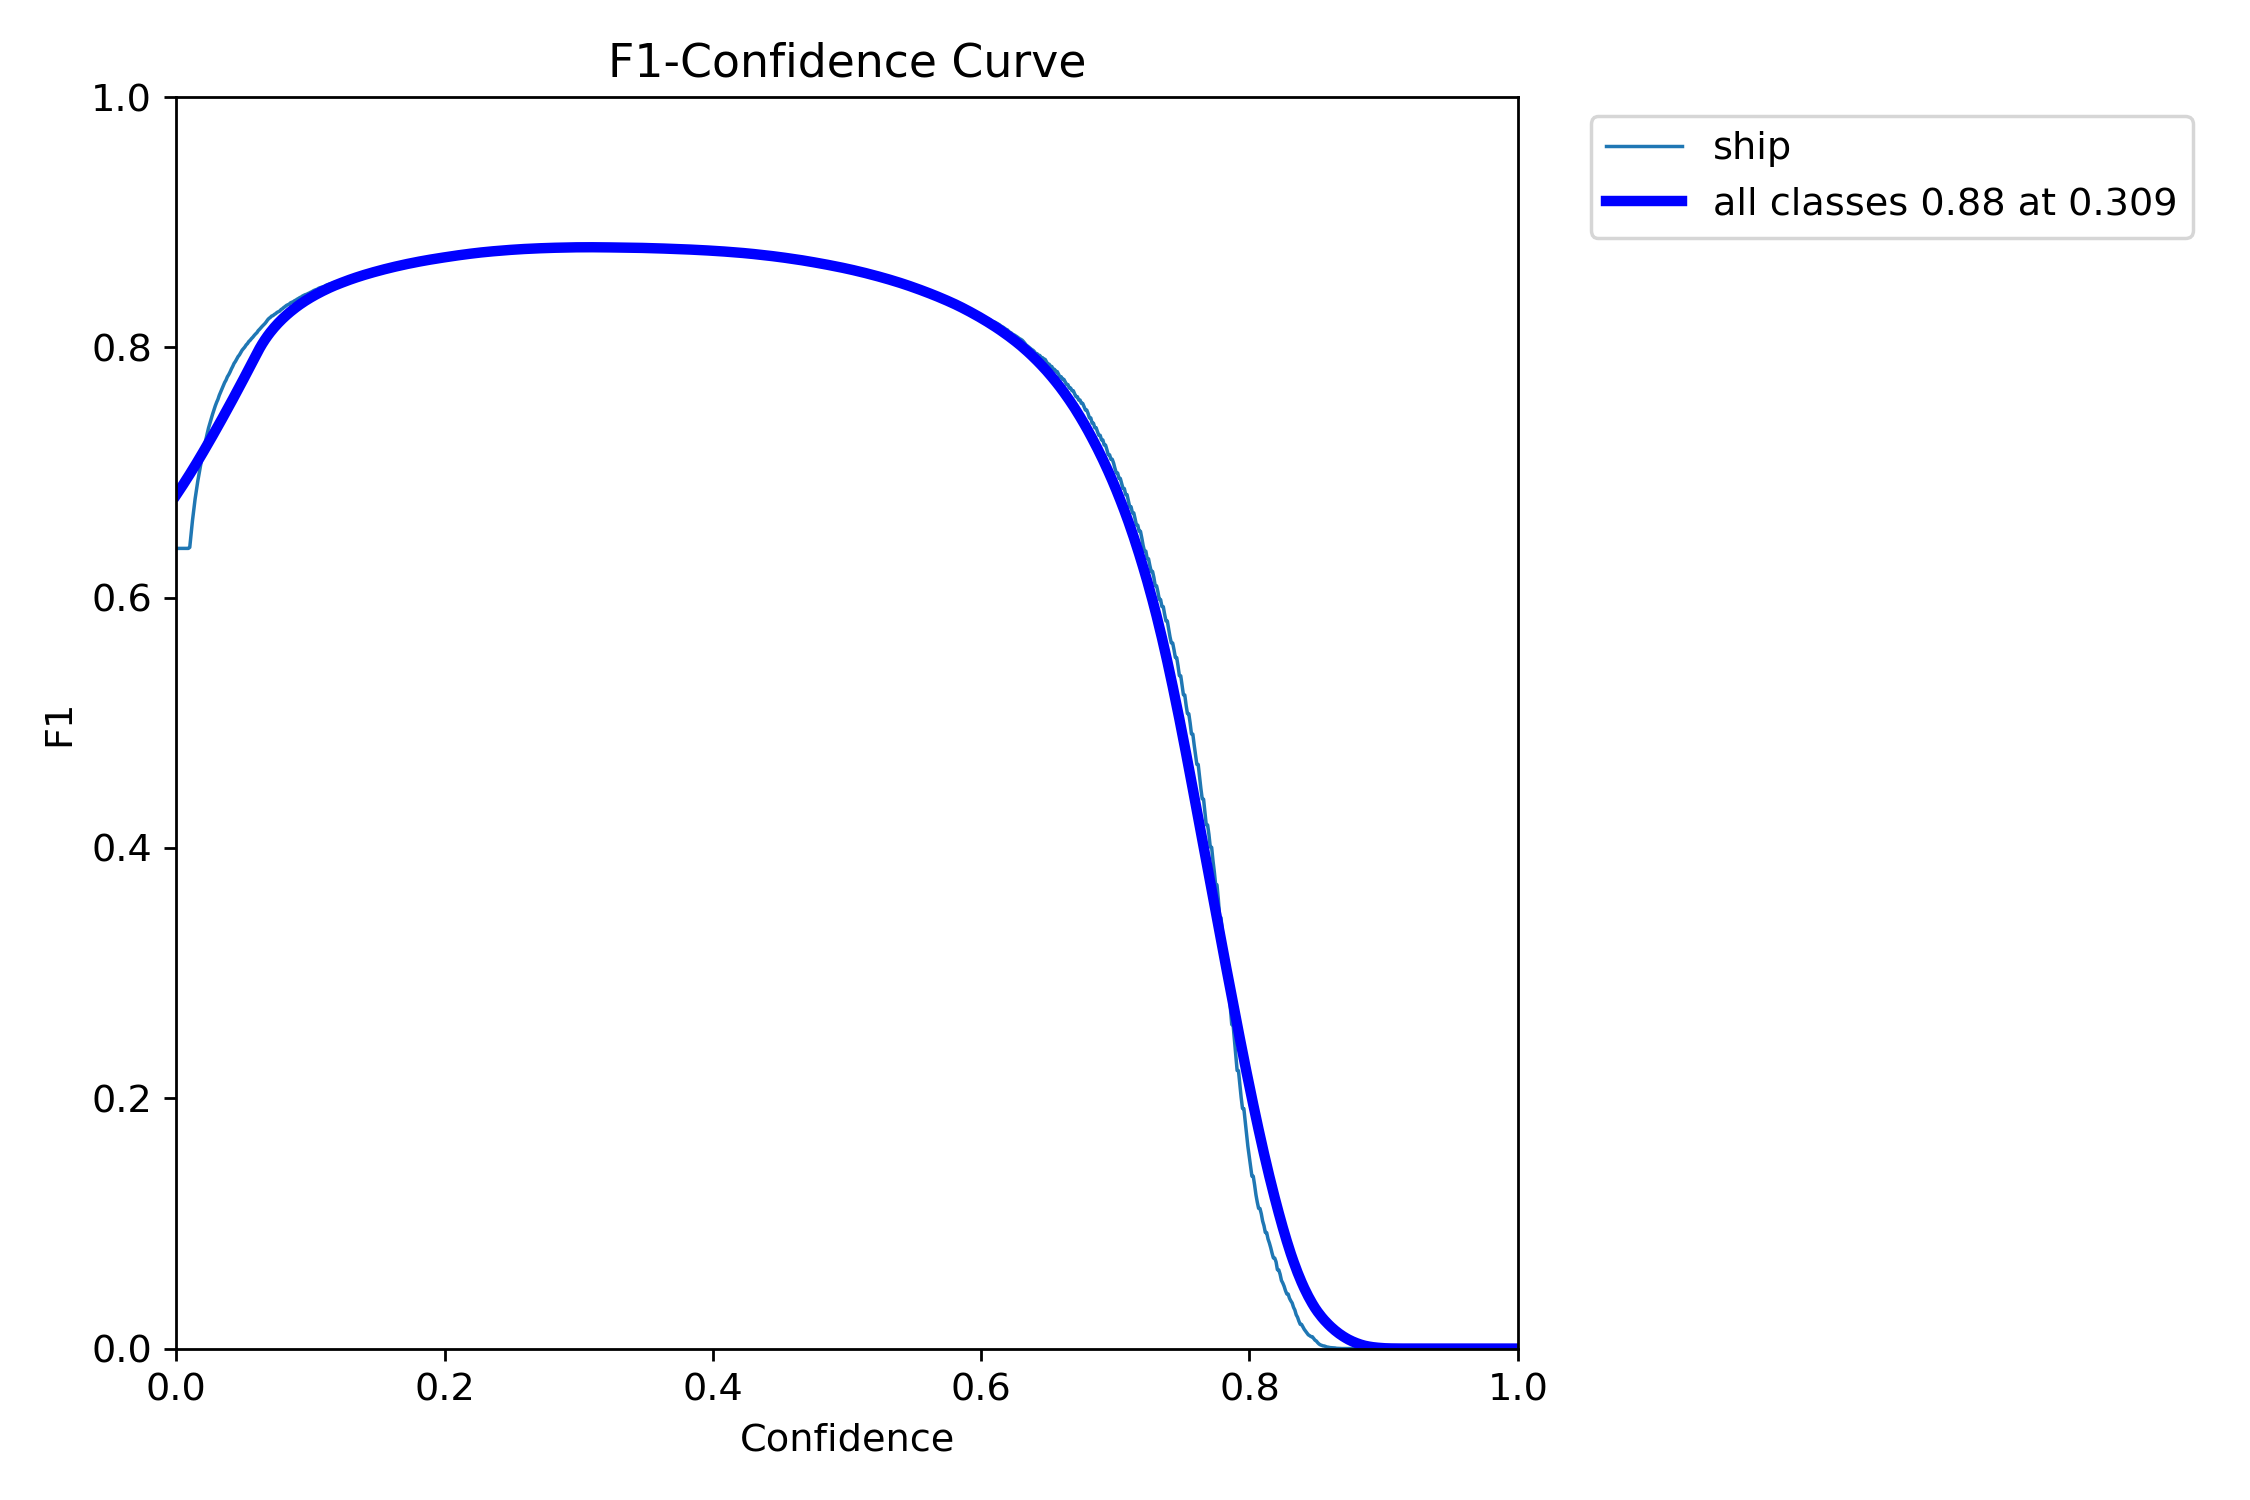

BoxPR_curve.png


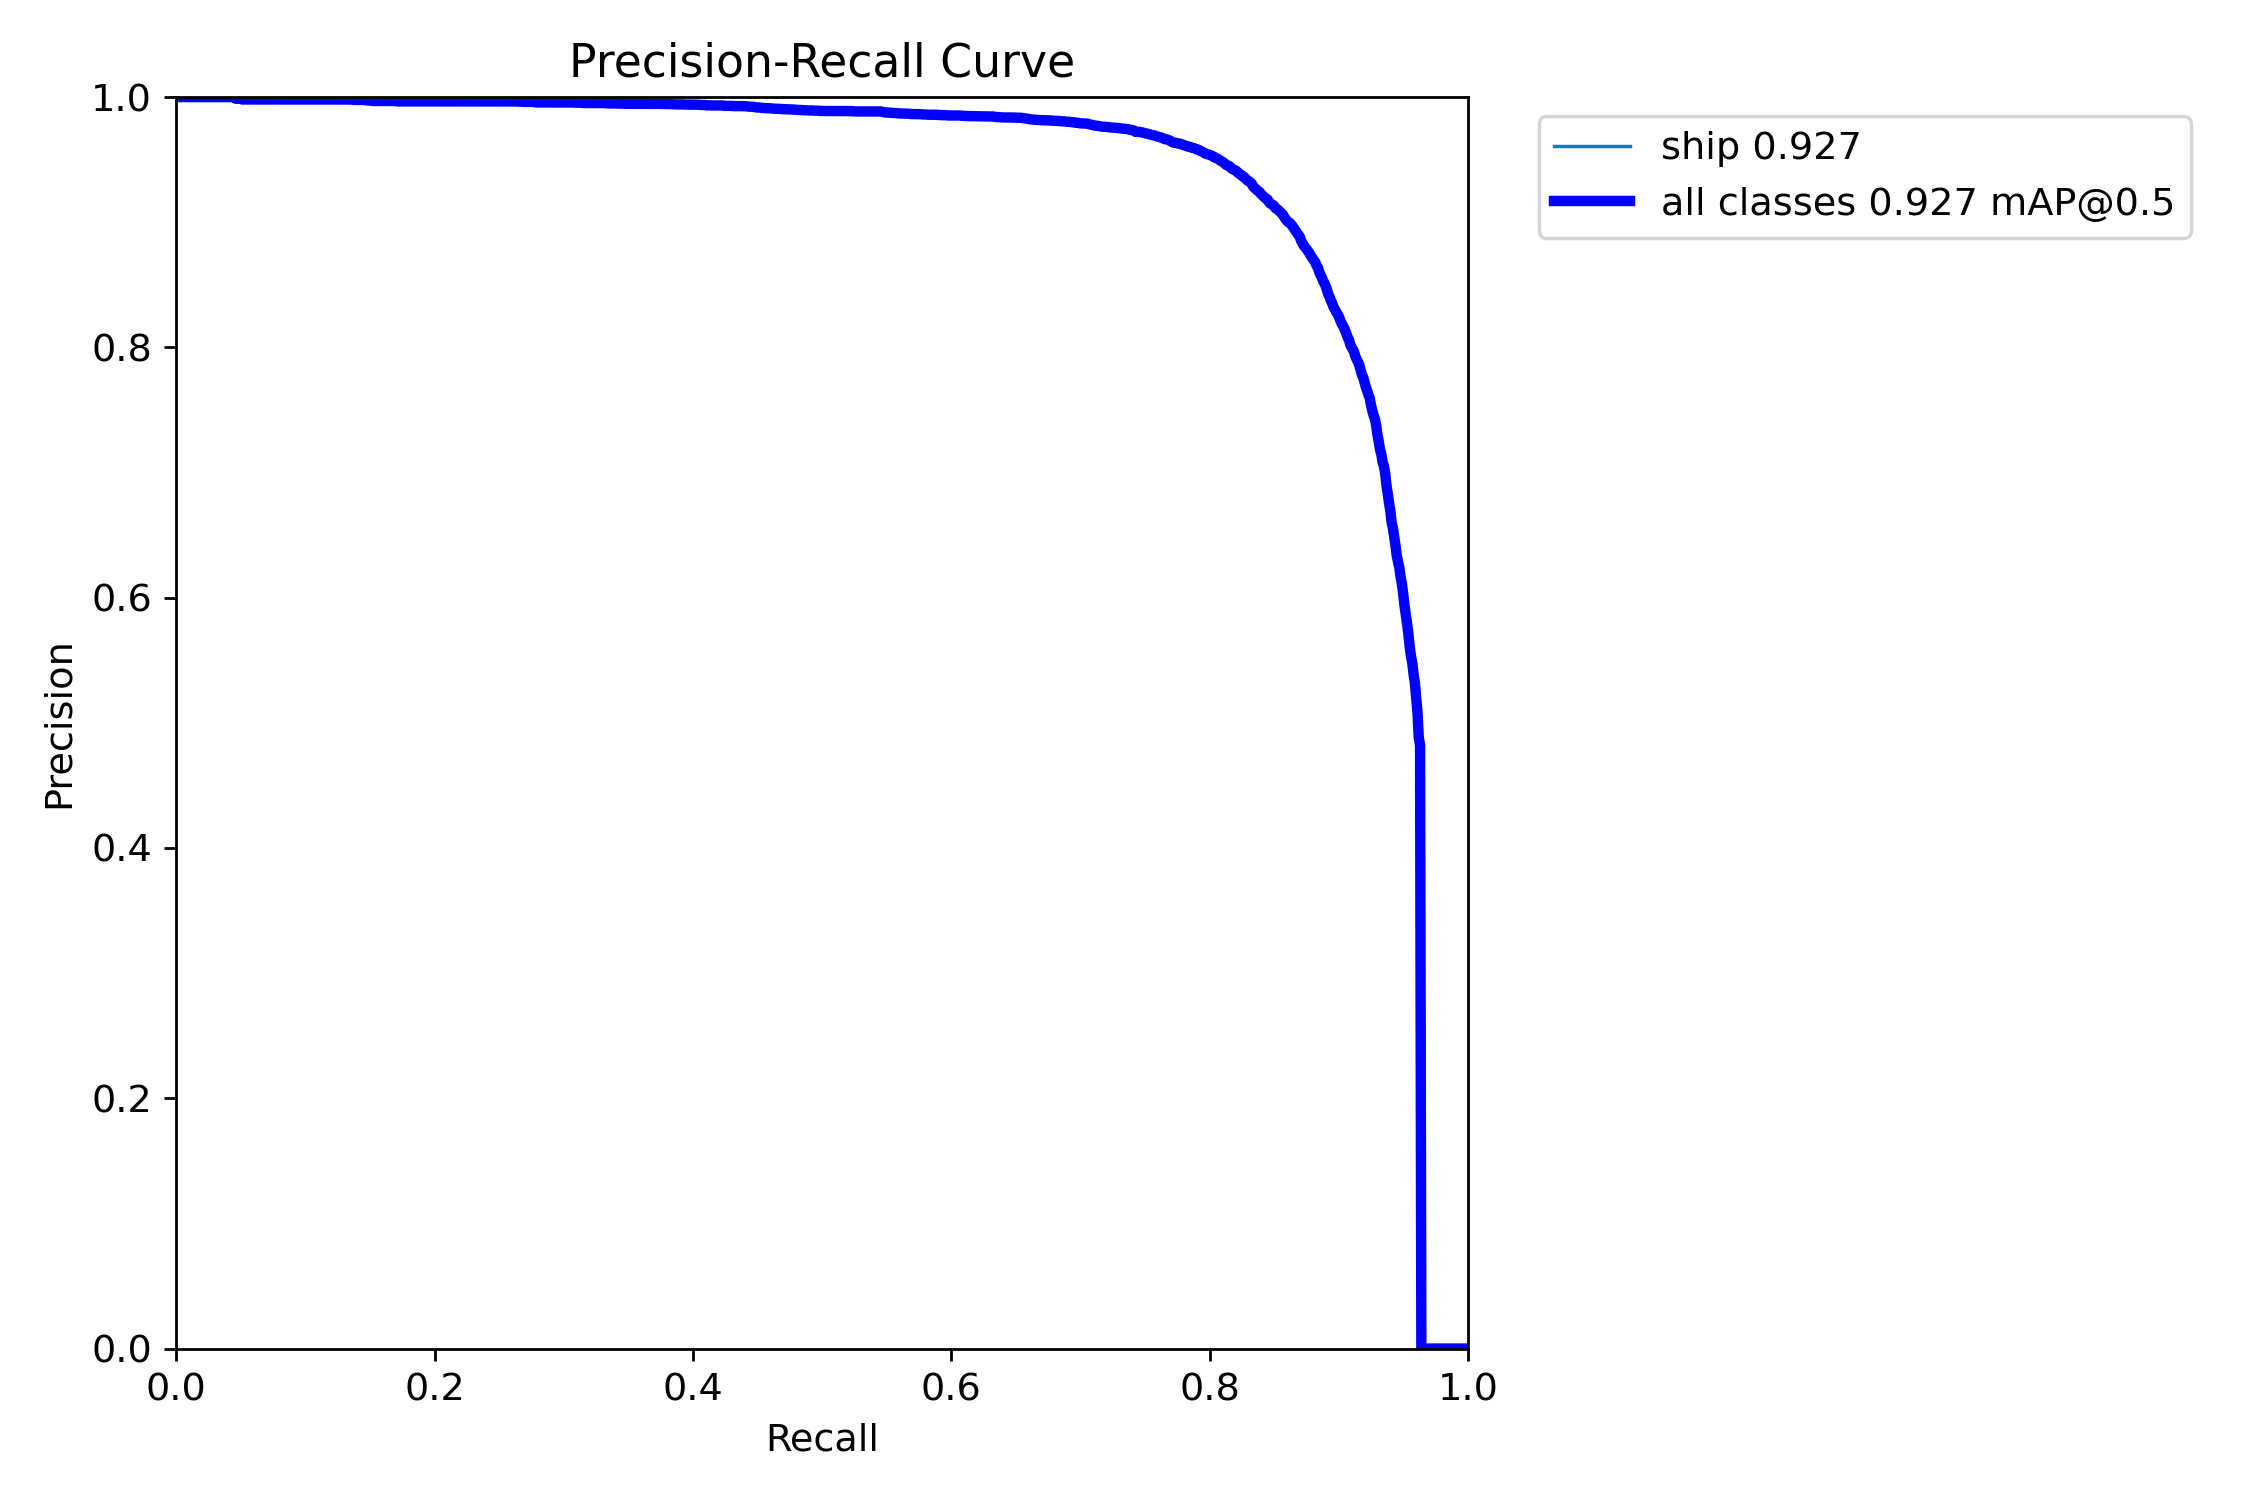

BoxP_curve.png


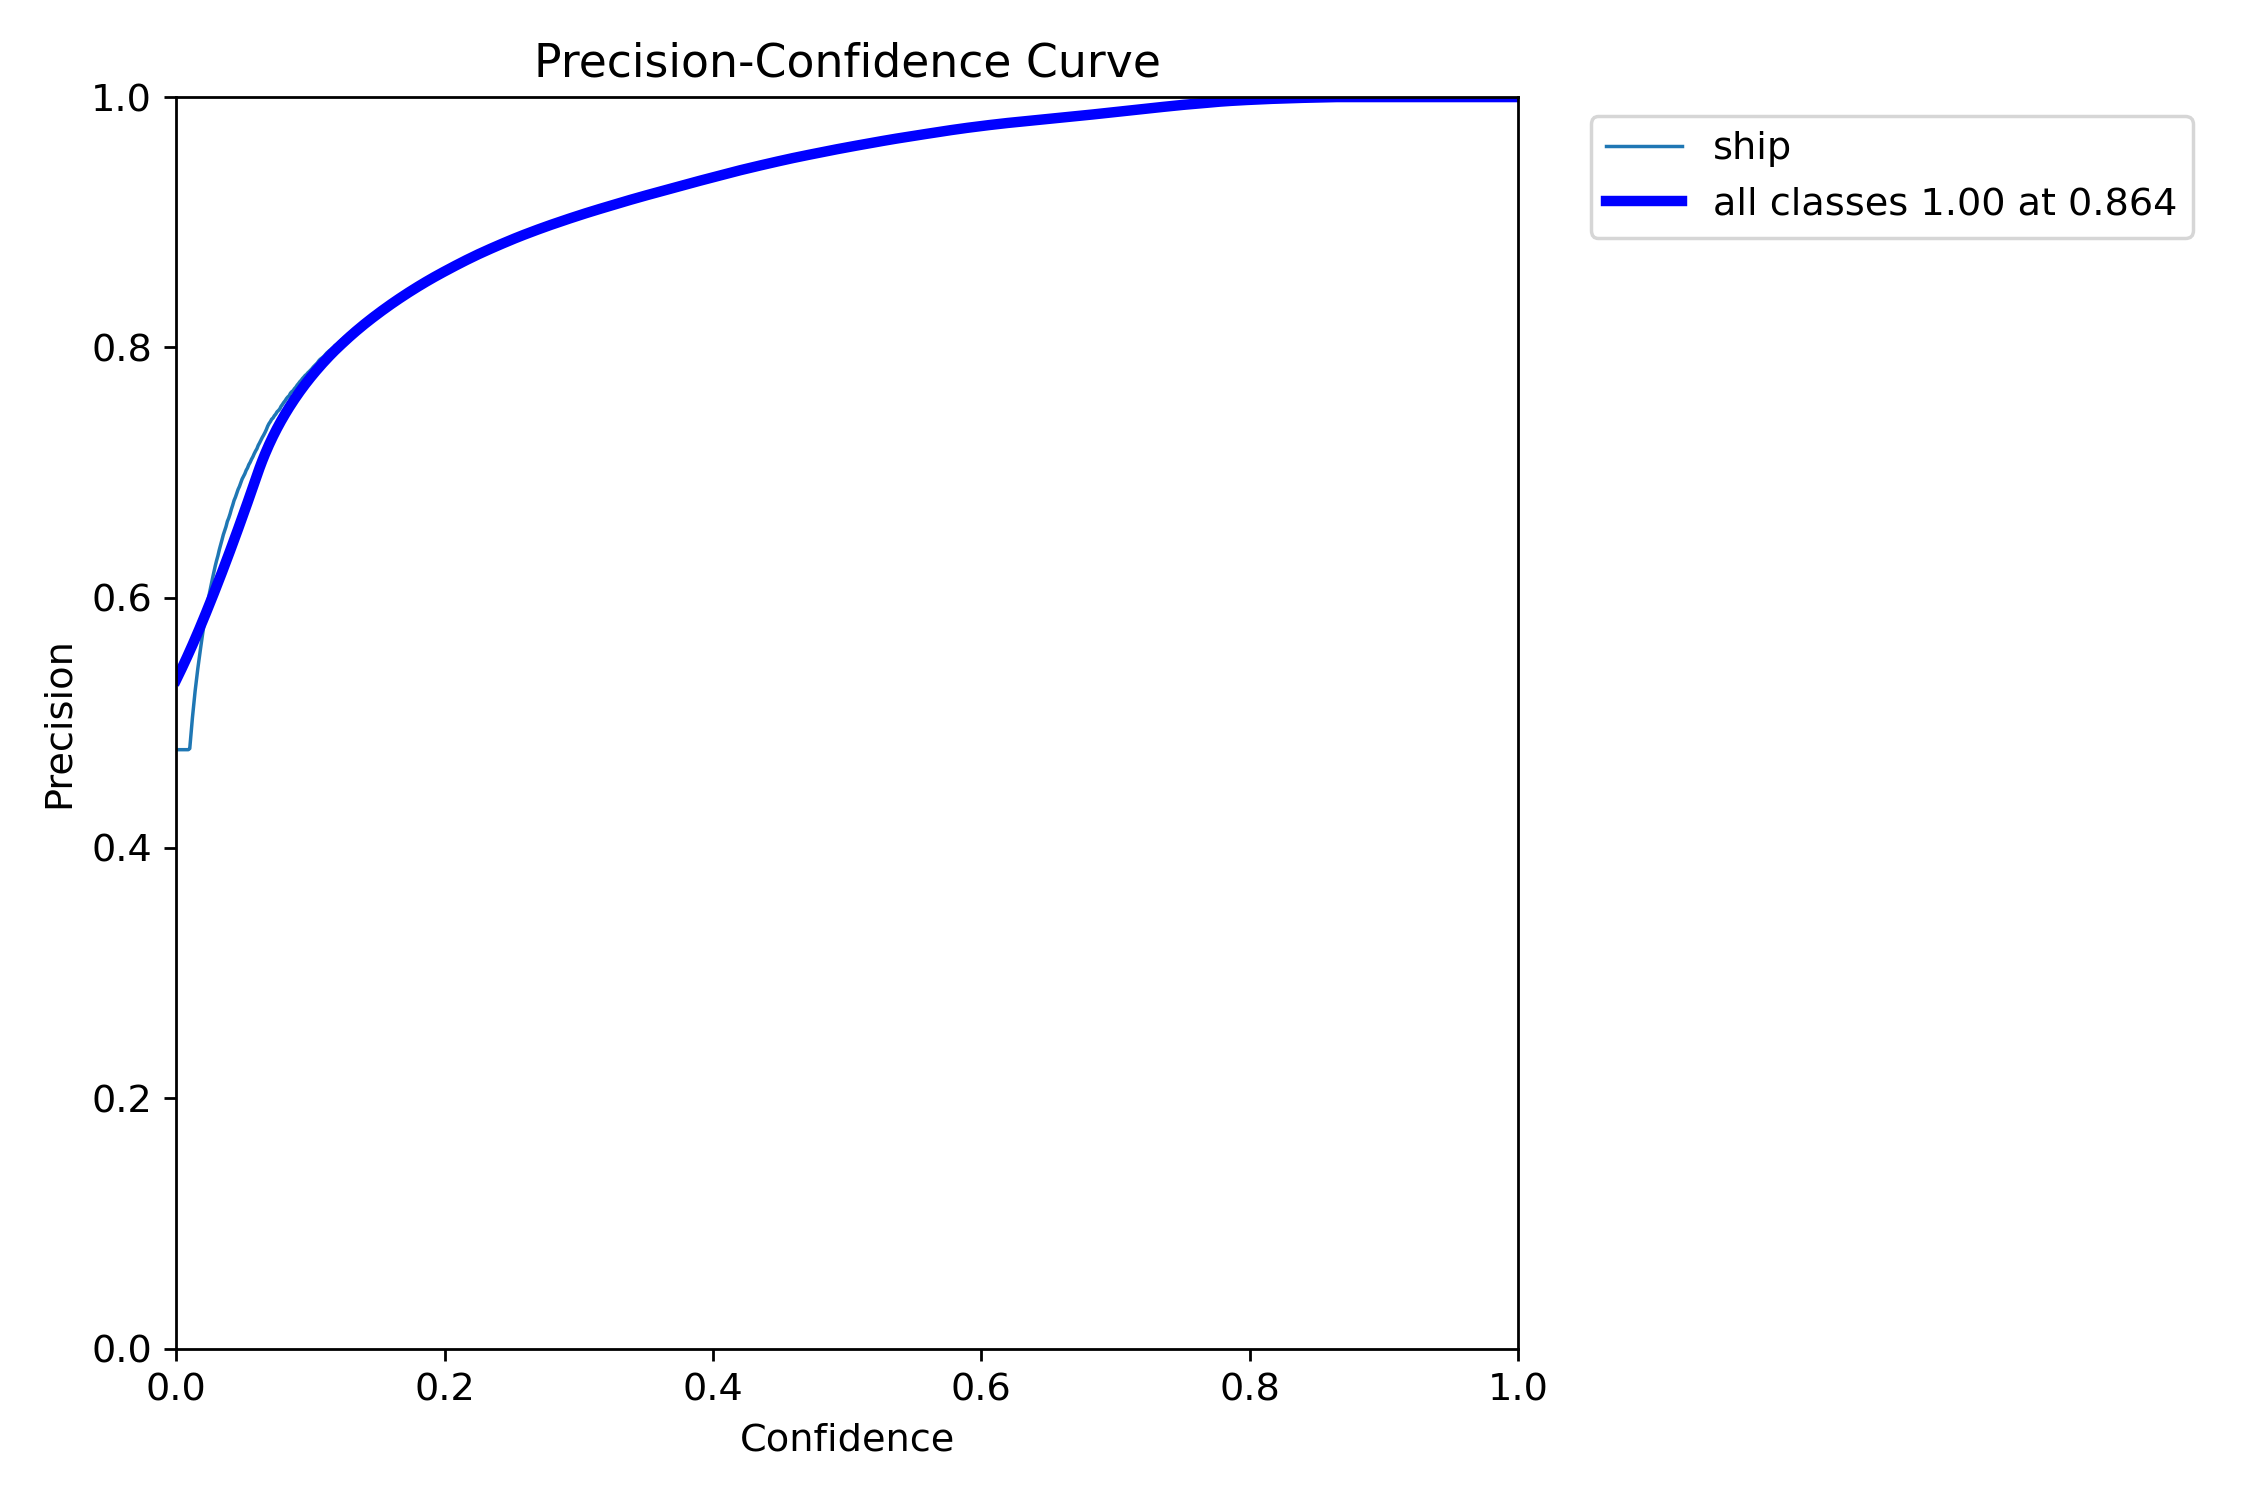

BoxR_curve.png


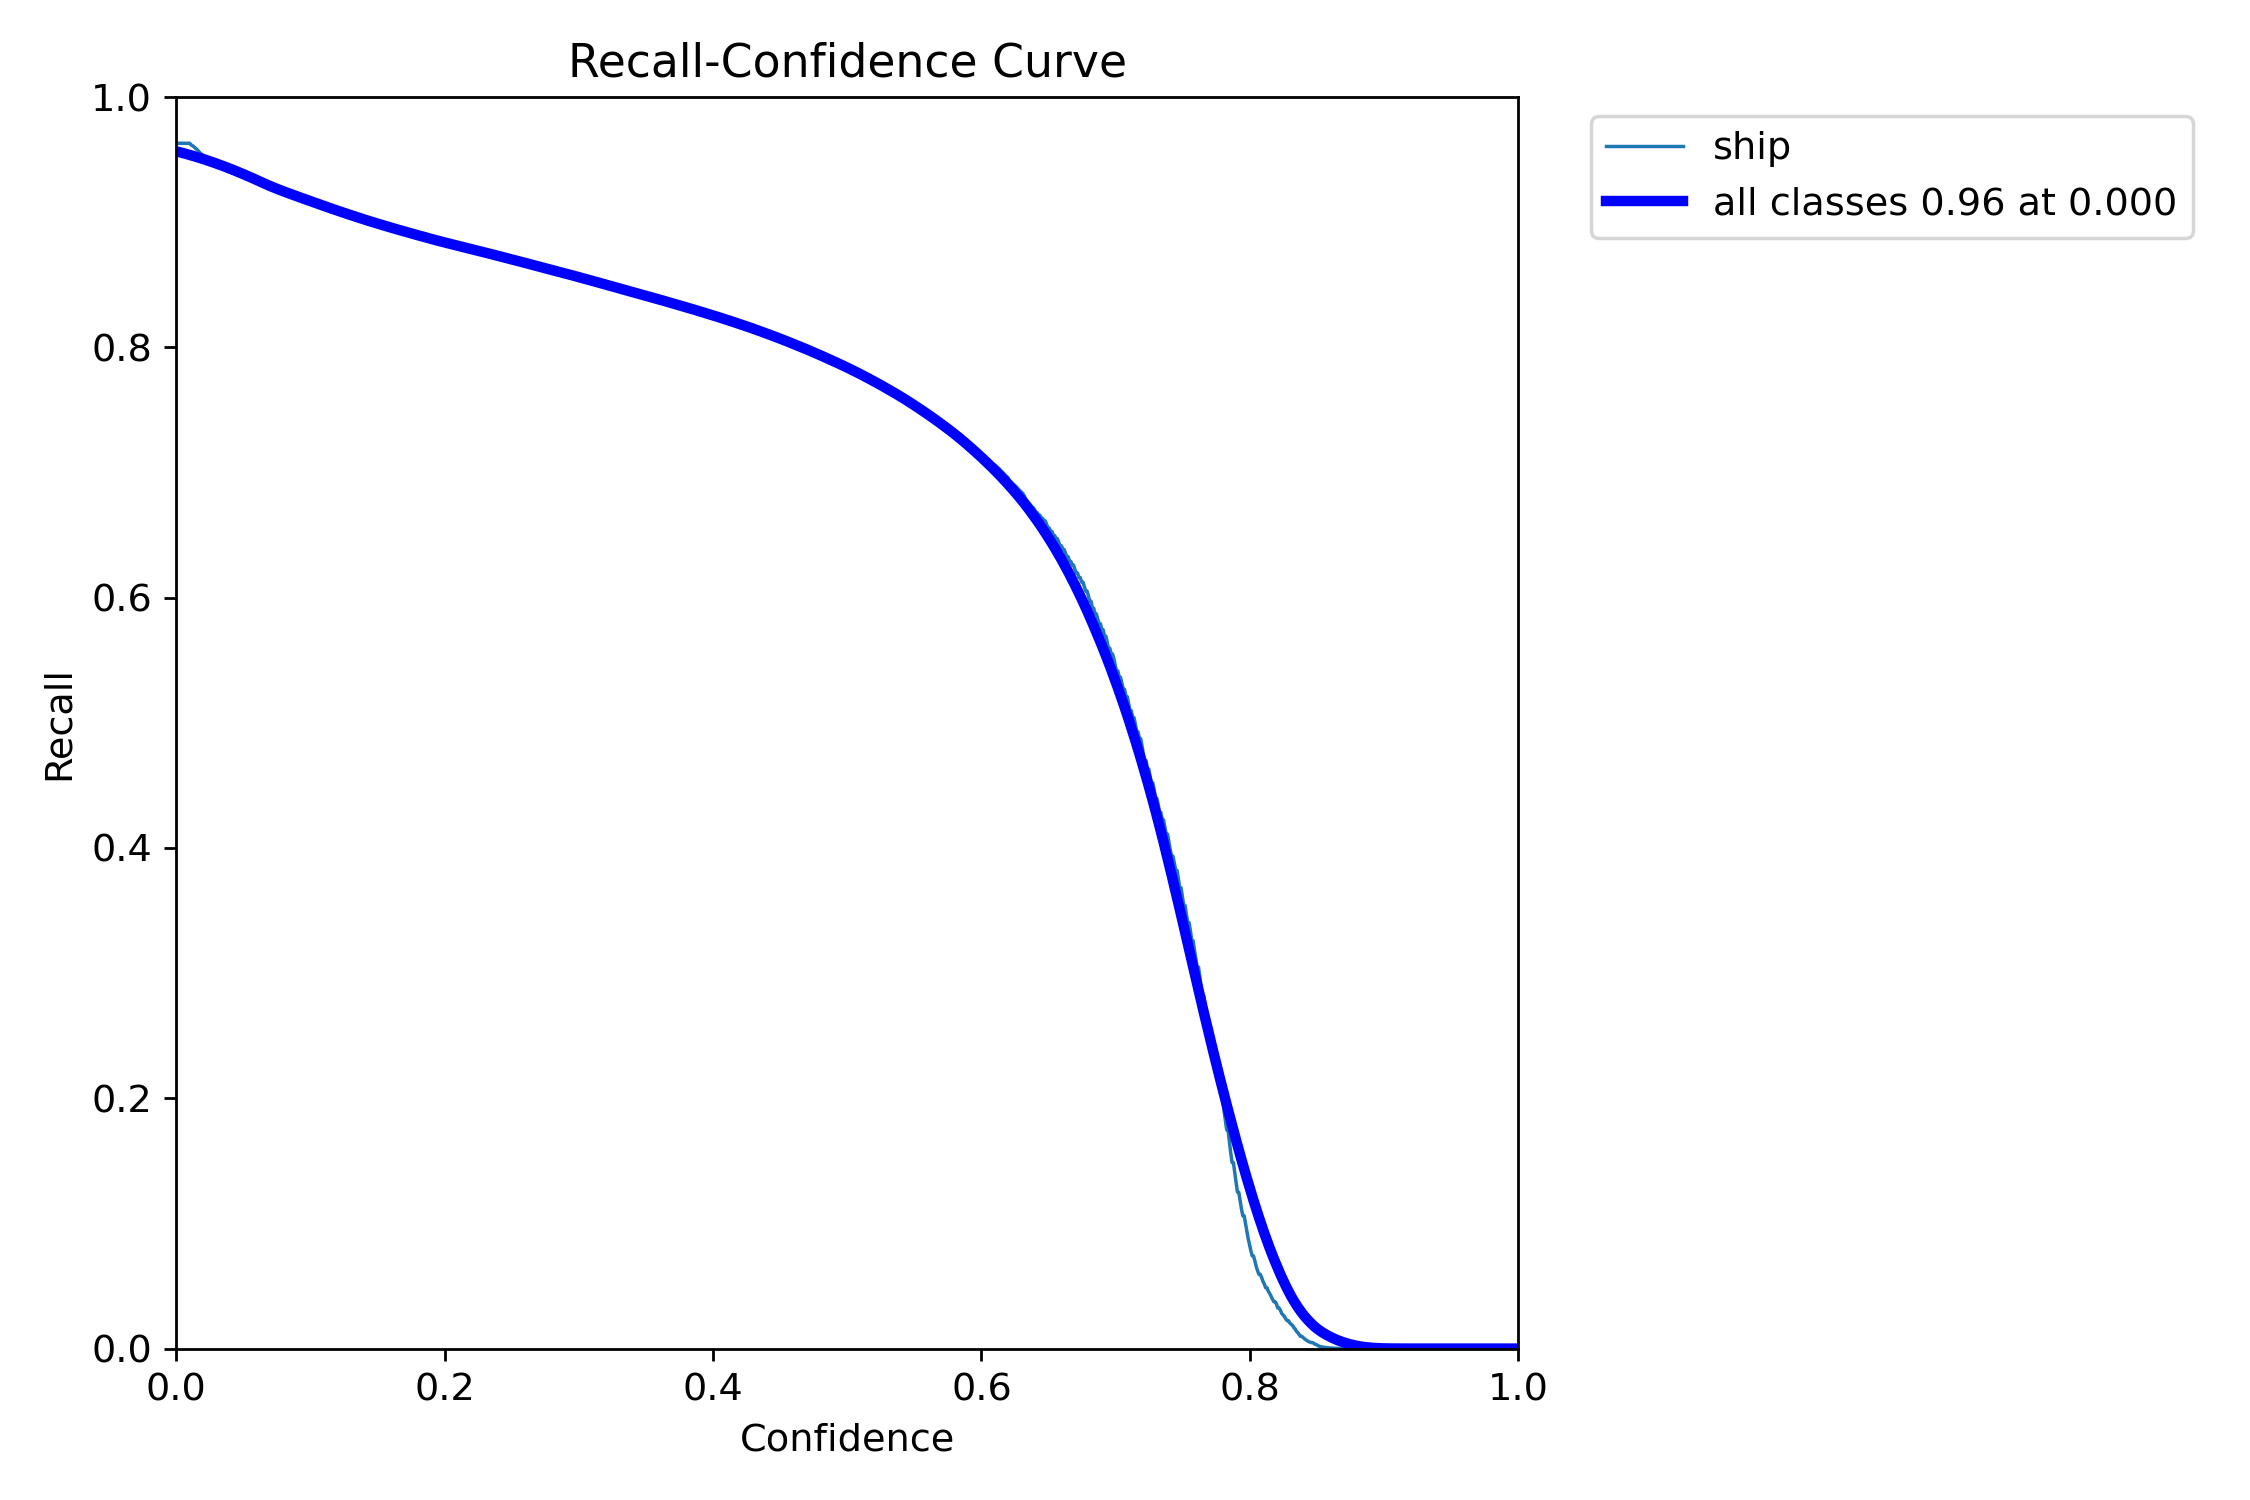

confusion_matrix.png


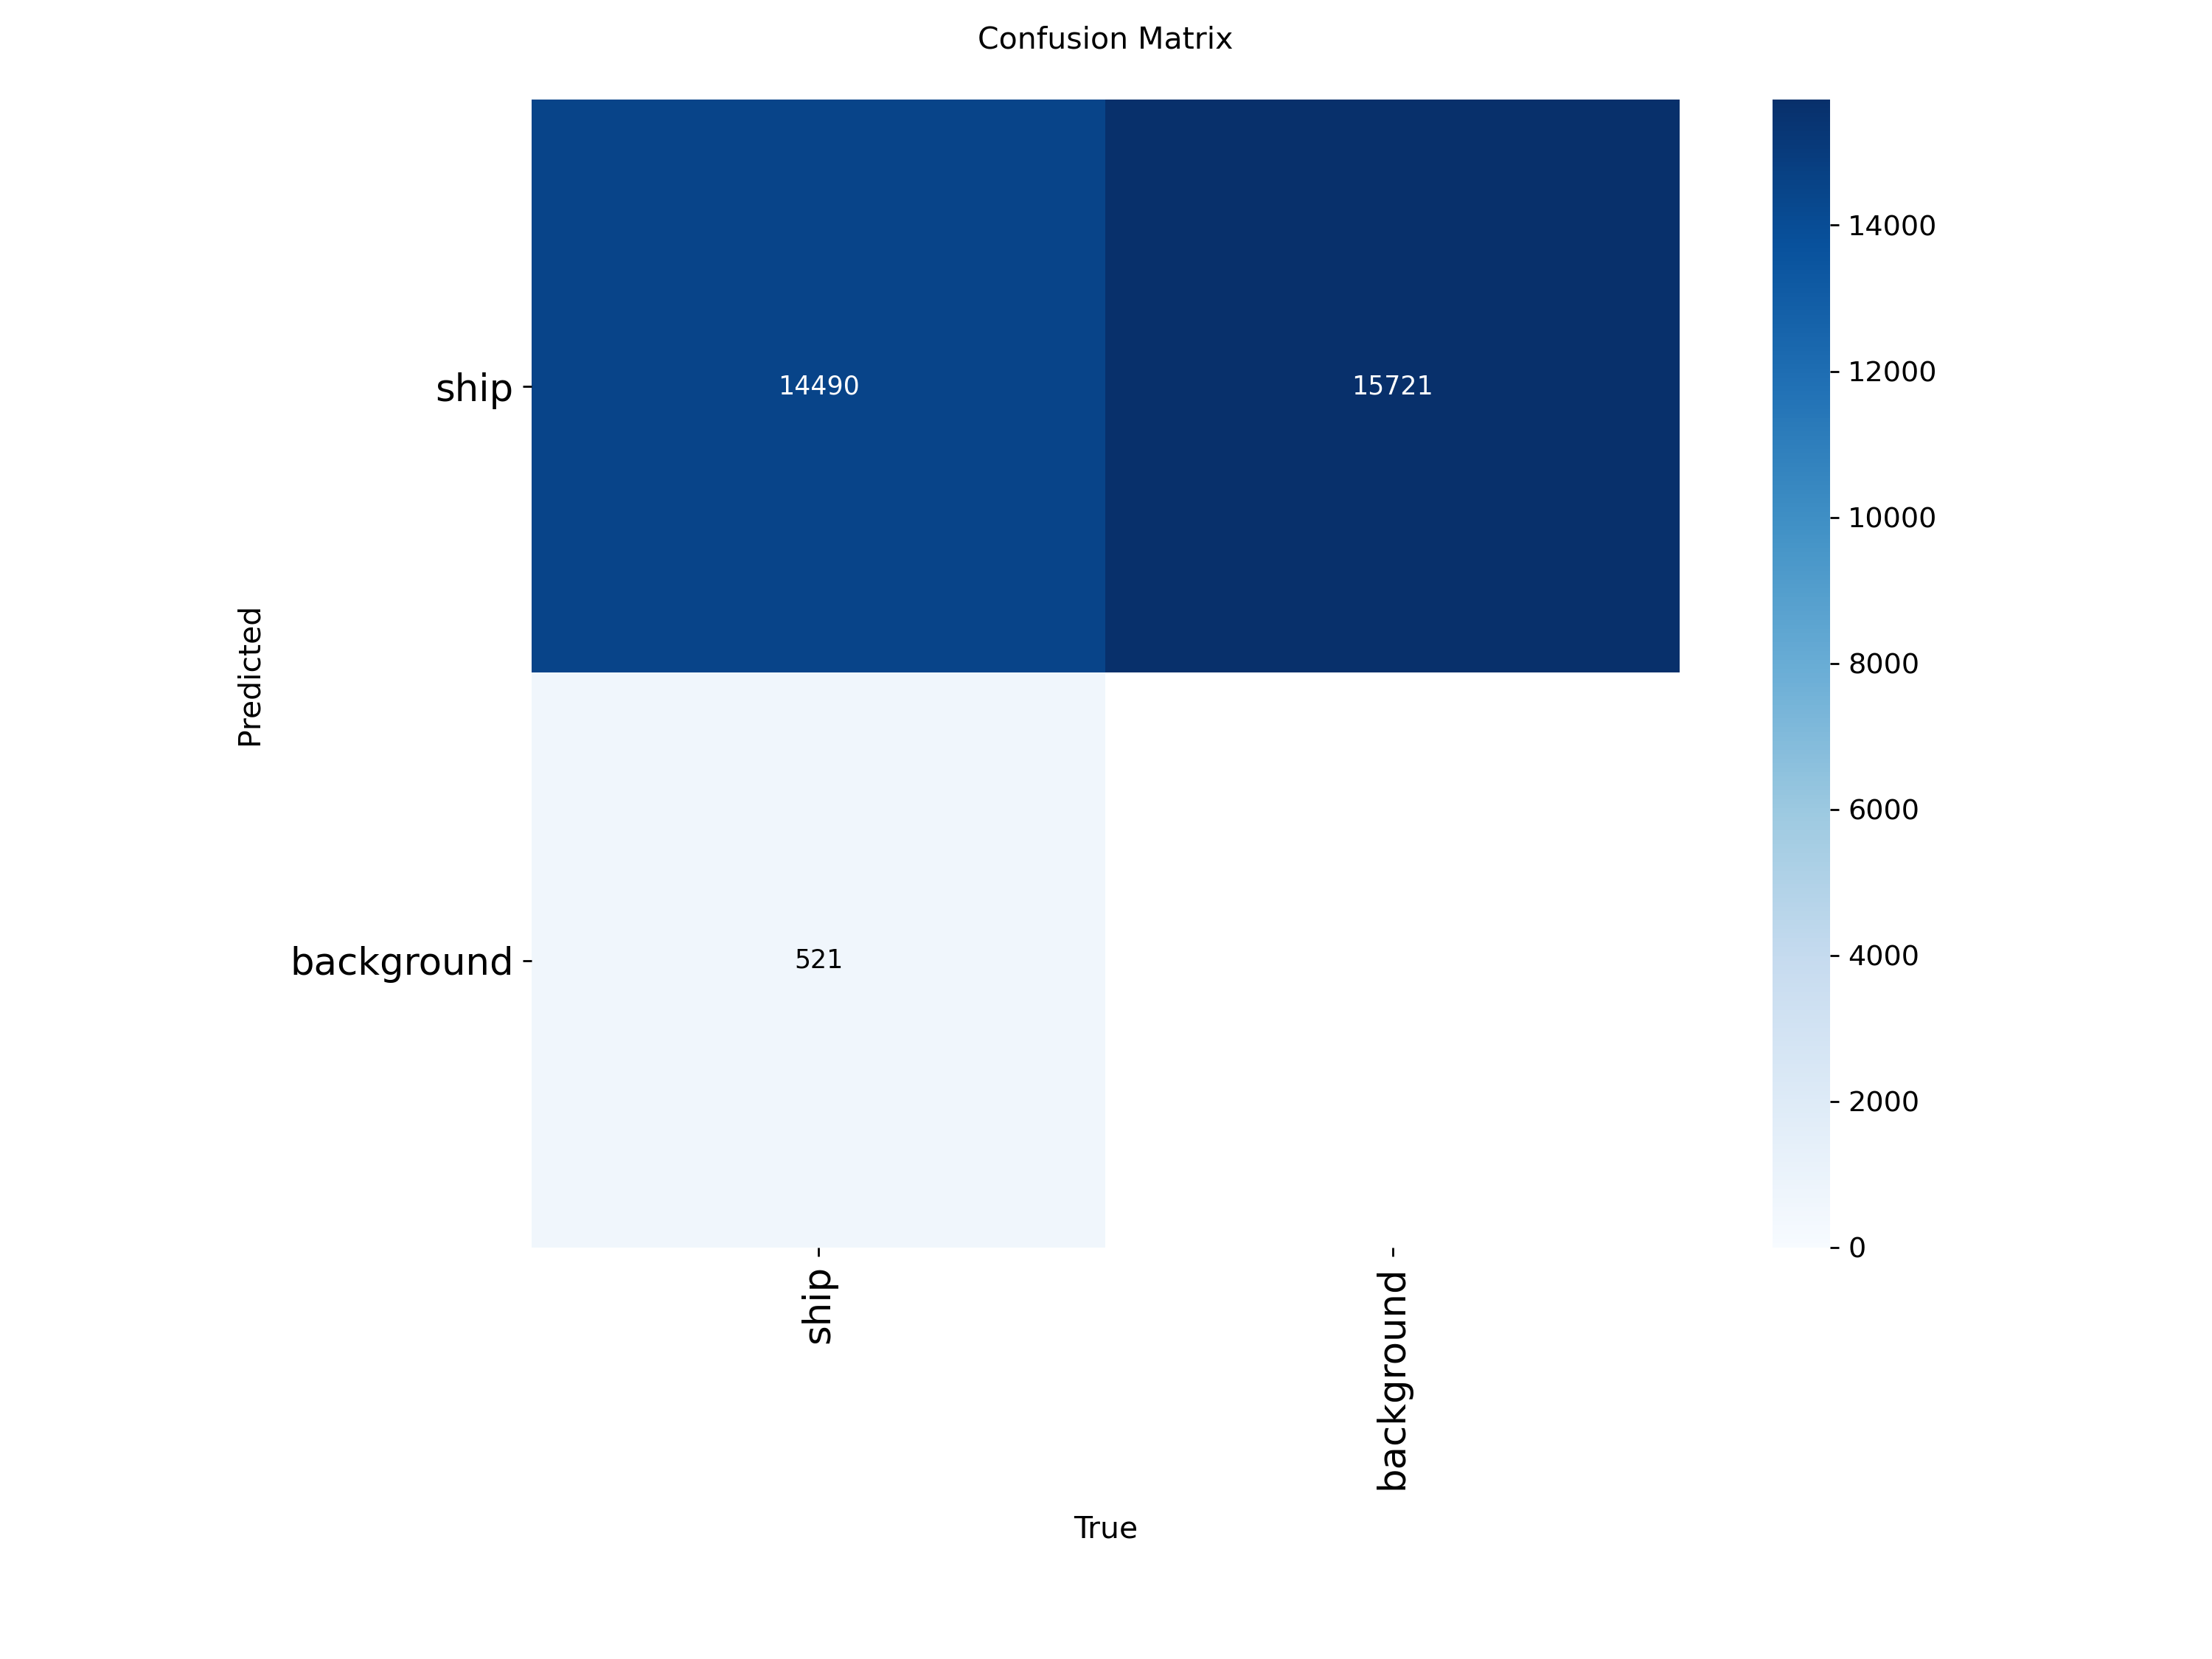

confusion_matrix_normalized.png


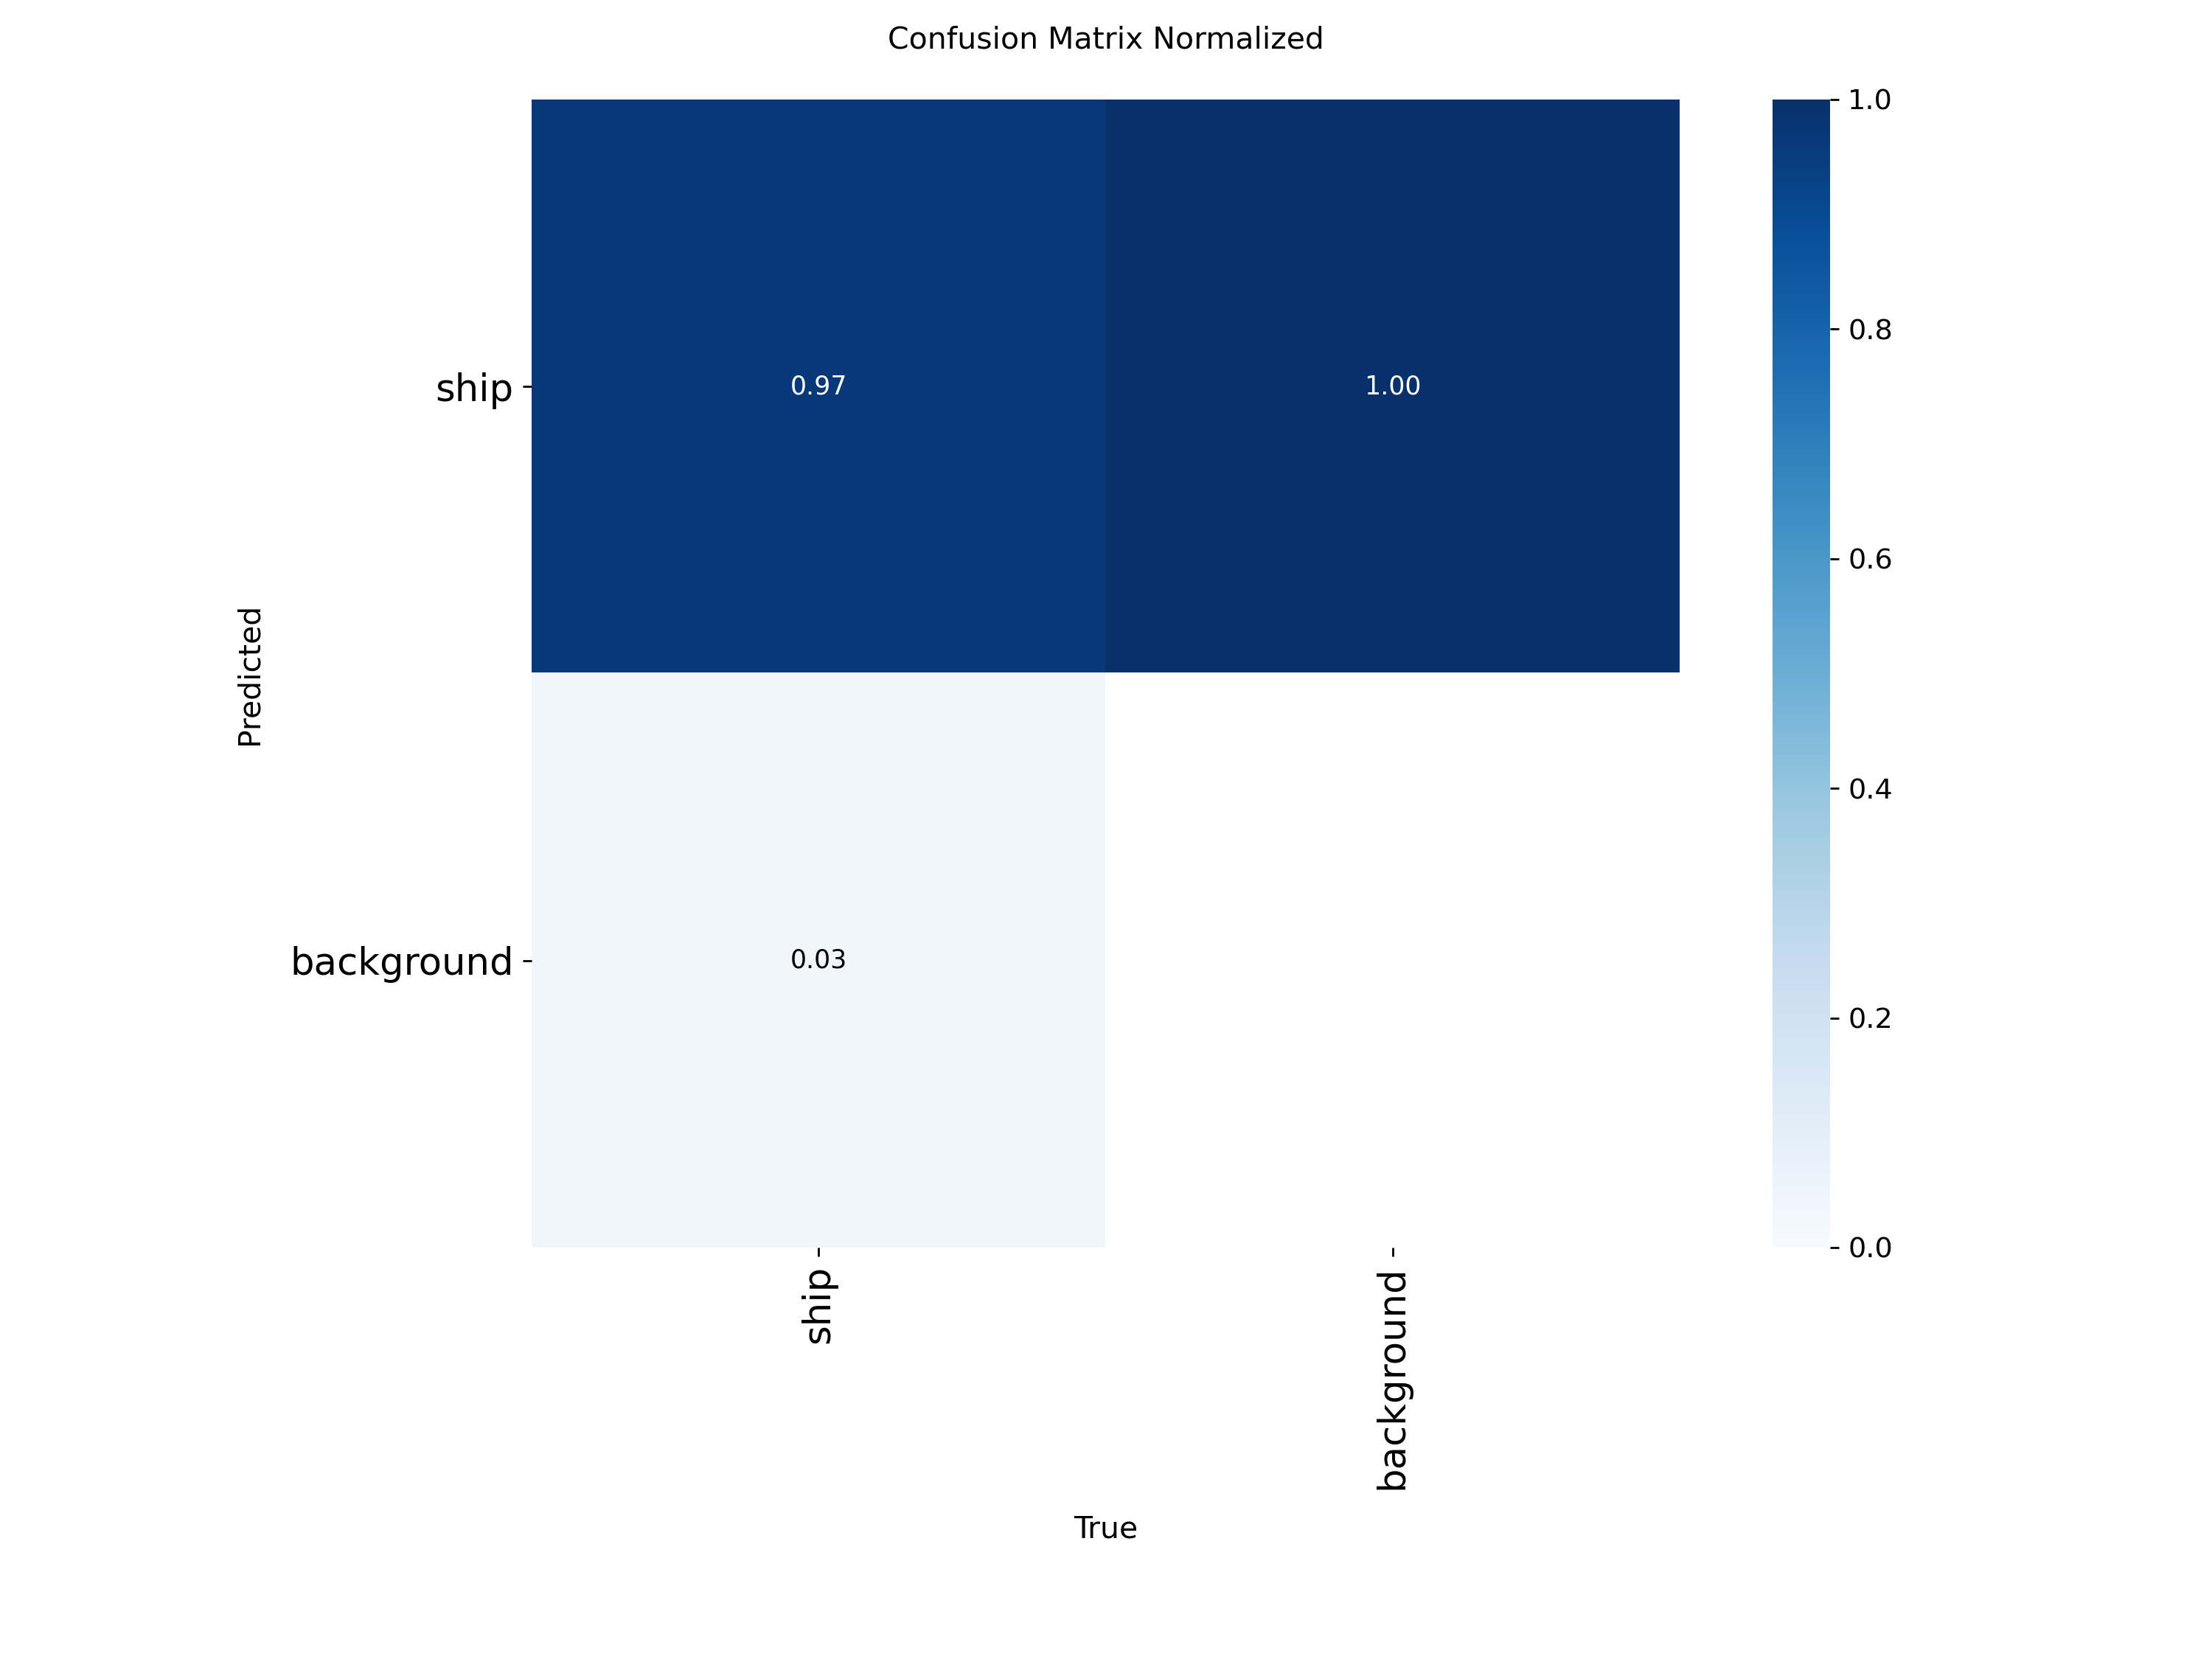

results.png


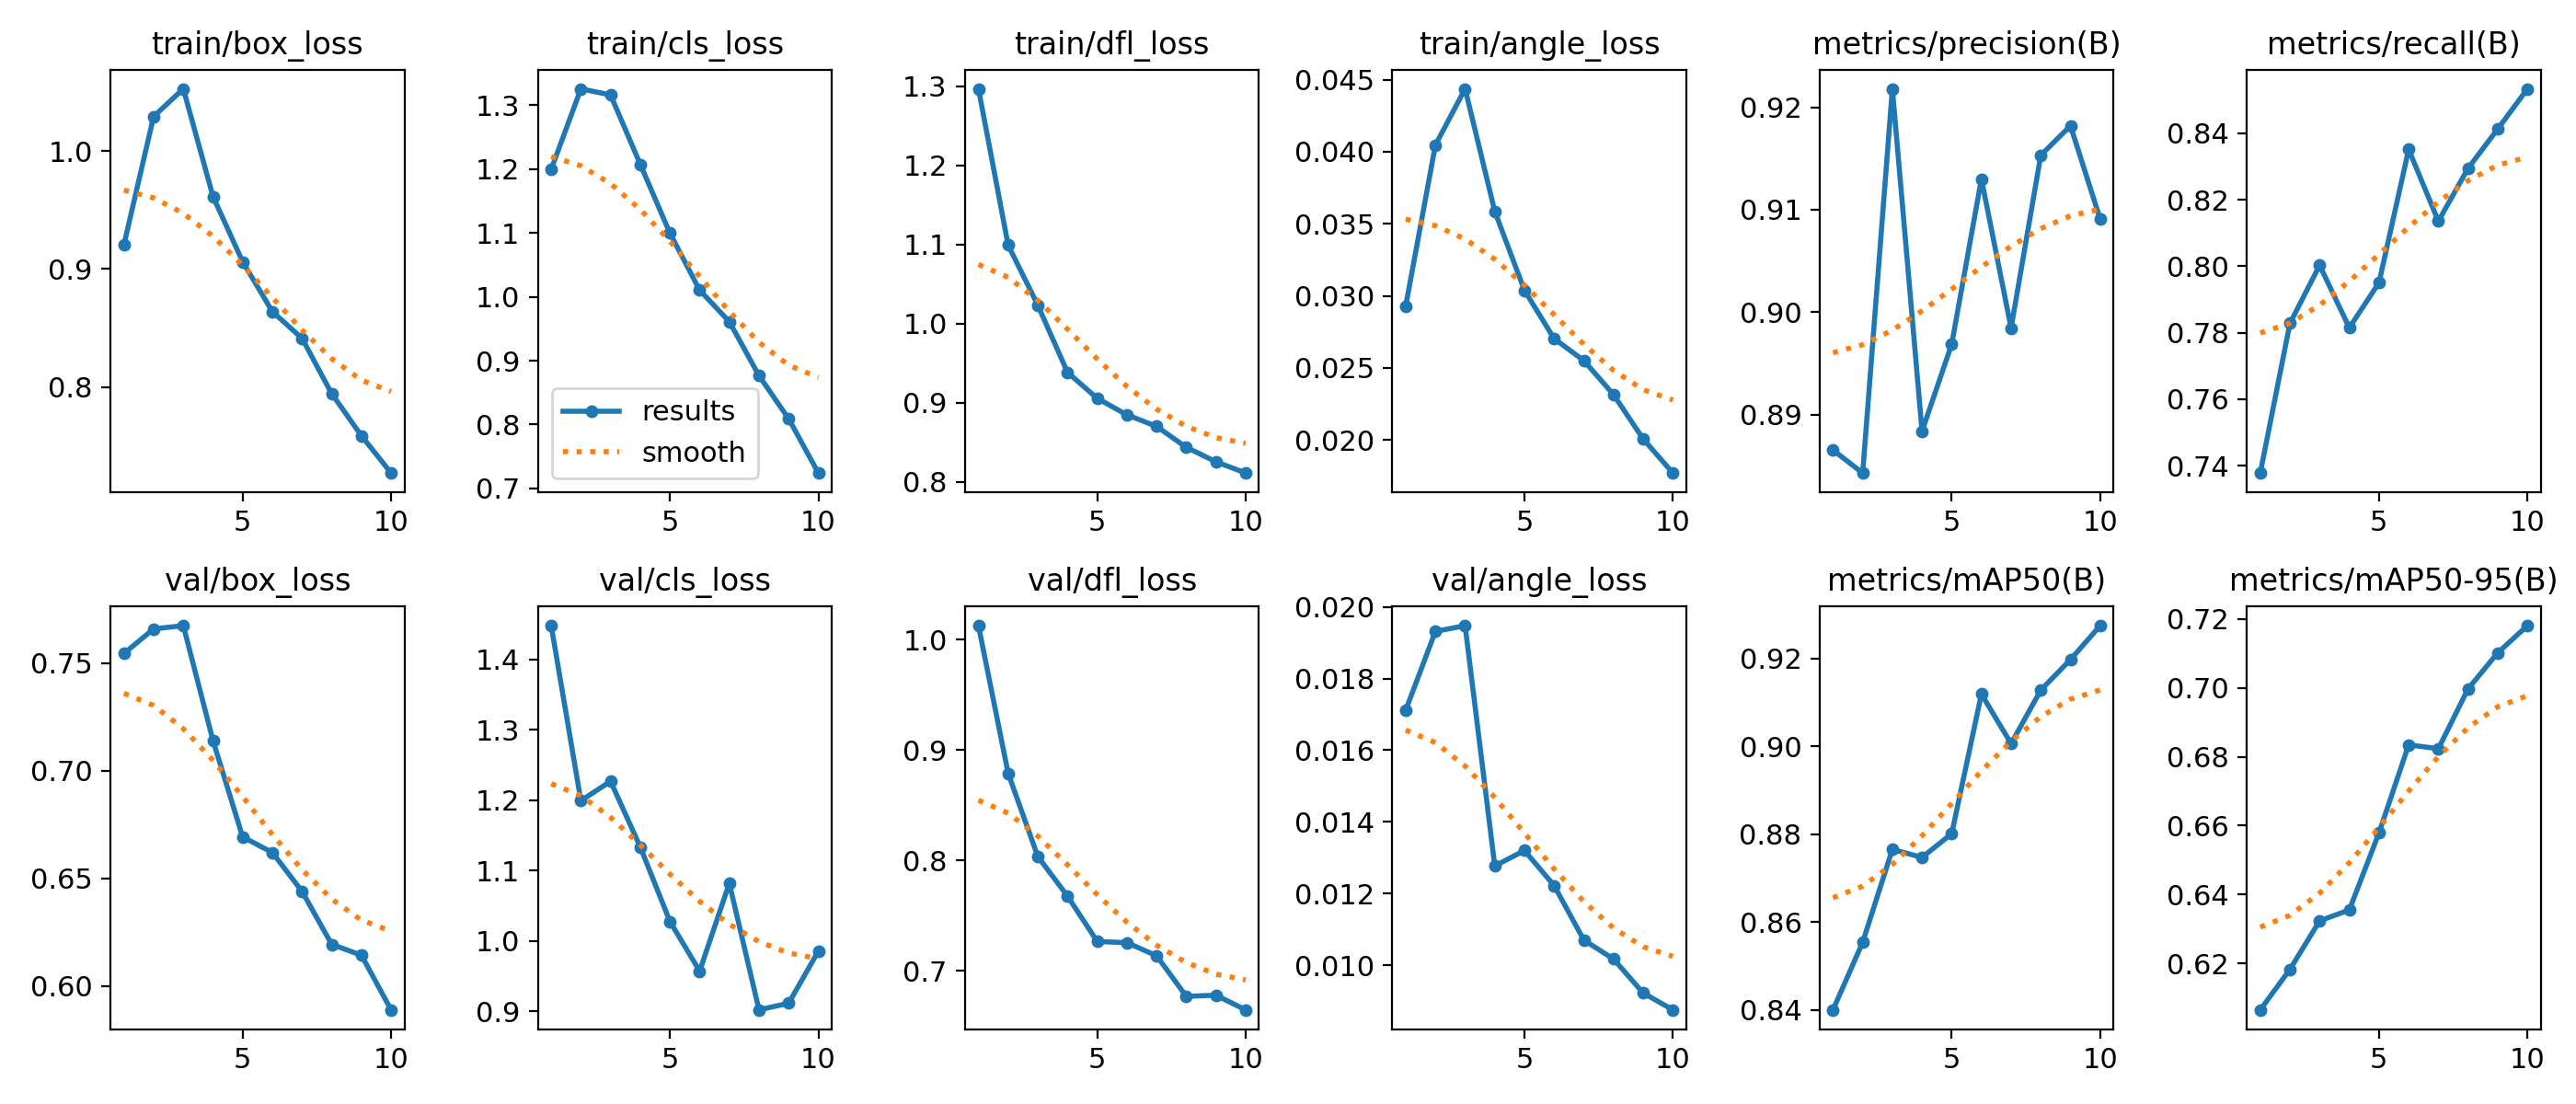

In [ ]:
from pathlib import Path
from IPython.display import display, Image

results_dir = RUN_DIR

plot_files = sorted(results_dir.glob("*.png"))

print("Training plots found:", len(plot_files))

for plot_path in plot_files:
    print(plot_path.name)
    display(Image(filename=str(plot_path)))

save training locally

In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

training_zip = Path("/content/dota_v15_training_backup.zip")

with zipfile.ZipFile(
    training_zip, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in RUN_DIR.rglob("*"):
        if path.is_file():
            archive.write(
                path,
                arcname=str(path.relative_to(PROJECT_DIR))
            )

print("Training backup created:", training_zip)
files.download(str(training_zip))


Training backup created: /content/dota_v15_training_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Validate the model (on Dotav1.5 validaiton split)

In [ ]:
from pathlib import Path

val_results = best_model.val(
    data="/content/dota_v15_ships_tiled/ships_tiled.yaml",
    split="val",
    imgsz=512,
    batch=4,
    device=0,
    plots=True,
    max_det=2000,
    project=str(PROJECT_DIR),
    name="validation",
    exist_ok=True
)

print("\n--- Tiled Model Validation Results ---")
print(f"Precision:  {val_results.box.mp:.4f}")
print(f"Recall:     {val_results.box.mr:.4f}")
print(f"mAP50:      {val_results.box.map50:.4f}")
print(f"mAP50-95:   {val_results.box.map:.4f}")

val_dir = Path(str(val_results.save_dir))
print("Validation outputs:", val_dir)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-obb summary (fused): 109 layers, 9,699,174 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2491.4±1298.6 MB/s, size: 121.6 KB)
val: Scanning /content/dota_v15_ships_tiled/labels/val.cache... 4144 images, 2805 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4144/4144 1.2Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1036/1036 17.2it/s 1:00
                   all       4144      15011      0.909      0.853      0.927      0.718
Speed: 0.8ms preprocess, 9.3ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/ship_detection/validation

--- Tiled Model Validation Results ---
Precision:  0.9094
Recall:     0.8530
mAP50:      0.9275
mAP50-95:   0.7180
Validation outputs: /content/ship_detection/validation


Evaluate the model on the DOTA v1.5 test split

In [ ]:
test_results = best_model.val(
    data="/content/dota_v15_ships_tiled/ships_tiled.yaml",
    split="test",
    imgsz=512,
    batch=4,
    device=0,
    conf=0.001,
    max_det=2000,
    plots=True,
    project=str(PROJECT_DIR),
    name="test",
    exist_ok=True
)

print("\n--- Tiled Model Test Results ---")
print(f"Precision:  {test_results.box.mp:.4f}")
print(f"Recall:     {test_results.box.mr:.4f}")
print(f"mAP50:      {test_results.box.map50:.4f}")
print(f"mAP50-95:   {test_results.box.map:.4f}")

test_dir = Path(str(test_results.save_dir))
print("Test outputs:", test_dir)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-obb summary (fused): 109 layers, 9,699,174 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1408.0±479.6 MB/s, size: 66.0 KB)
val: Scanning /content/dota_v15_ships_tiled/labels/test... 1998 images, 1300 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1998/1998 1.6Kit/s 1.3s
val: New cache created: /content/dota_v15_ships_tiled/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 500/500 16.1it/s 31.0s
                   all       1998      13248      0.944      0.888      0.941      0.751
Speed: 0.8ms preprocess, 9.2ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/ship_detection/test

--- Tiled Model Test Results ---
Precision:  0.9438
Recall:     0.8878
mAP50:      0.9406
mAP50-95:   0.7512
Test outputs: /content/ship_detection/test


save val and test results locally

In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

evaluation_zip = Path("/content/dota_v15_evaluation_backup.zip")

folders_to_save = [
    RUN_DIR,
    PROJECT_DIR / "validation",
    PROJECT_DIR / "test"
]

with zipfile.ZipFile(
    evaluation_zip, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for folder in folders_to_save:
        if folder.exists():
            for path in folder.rglob("*"):
                if path.is_file():
                    archive.write(
                        path,
                        arcname=str(path.relative_to(PROJECT_DIR))
                    )

print("Evaluation backup created:", evaluation_zip)
files.download(str(evaluation_zip))


Evaluation backup created: /content/dota_v15_evaluation_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

# Read metrics recorded during training
history_path = RUN_DIR / "results.csv"
history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

last_epoch = history.iloc[-1]

# Validation metrics recorded at the final training epoch
final_epoch_metrics = {
    "Precision": last_epoch["metrics/precision(B)"],
    "Recall": last_epoch["metrics/recall(B)"],
    "mAP50": last_epoch["metrics/mAP50(B)"],
    "mAP50-95": last_epoch["metrics/mAP50-95(B)"]
}

# Evaluate the best saved model on the validation split
val_metrics = {
    "Precision": val_results.box.mp,
    "Recall": val_results.box.mr,
    "mAP50": val_results.box.map50,
    "mAP50-95": val_results.box.map
}

# Evaluate the best saved model on the held-out test split
test_metrics = {
    "Precision": test_results.box.mp,
    "Recall": test_results.box.mr,
    "mAP50": test_results.box.map50,
    "mAP50-95": test_results.box.map
}

results_df = pd.DataFrame({
    "Final training-run validation (%)": {
        k: v * 100 for k, v in final_epoch_metrics.items()
    },
    "Best model validation (%)": {
        k: v * 100 for k, v in val_metrics.items()
    },
    "Best model test (%)": {
        k: v * 100 for k, v in test_metrics.items()
    }
})

print(results_df.round(2).to_string())
results_df.to_csv(PROJECT_DIR / "metrics_comparison.csv")

           Final training-run validation (%)  Best model validation (%)  Best model test (%)
Precision                              90.91                      90.94                94.38
Recall                                 85.33                      85.30                88.78
mAP50                                  92.75                      92.75                94.06
mAP50-95                               71.81                      71.80                75.12


Generate predictions on tiled test images

In [ ]:
results = best_model.predict(
    source="/content/dota_v15_ships_tiled/images/test",
    imgsz=512,
    conf=0.25,
    iou=0.7,
    batch=4,
    device=0,
    save=True,
    project=str(PROJECT_DIR),
    name="test_predictions",
    exist_ok=True
)

Display random annotated test tiles

Annotated test images found: 1998
97f7c238a2d983d093ba421aa6e7b761_171_x768_y1792.jpg


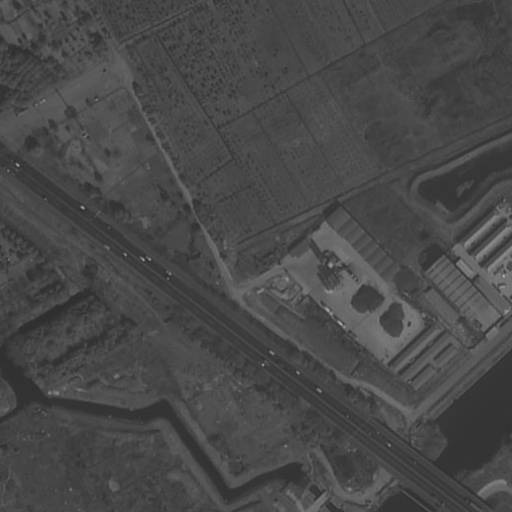

35e2e959dec2343cad96e086ede07a72_56_x512_y1024.jpg


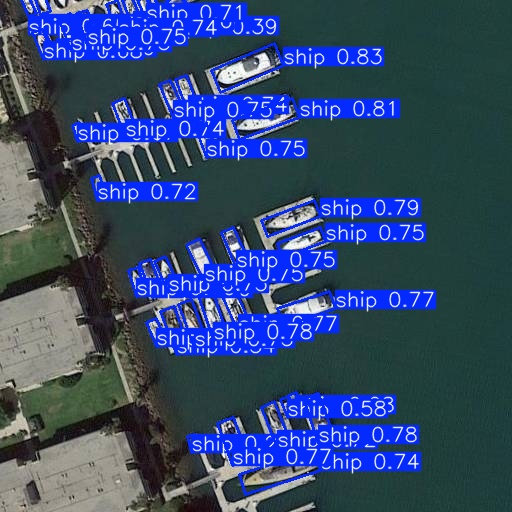

d95af113e64b9750c3eab891d61fdcb4_245_x592_y0.jpg


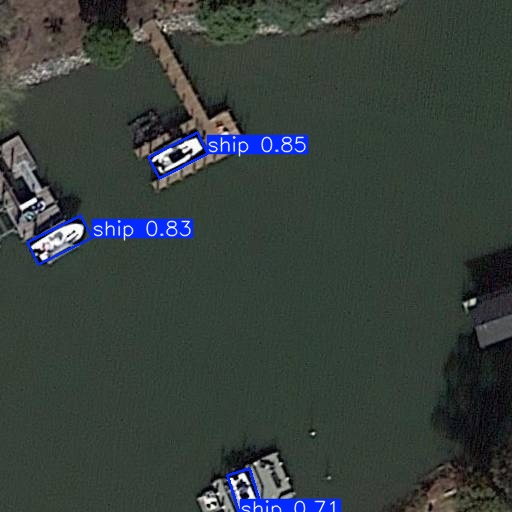

5bf76434d5657e371ad834d3d8e477d4_96_x1140_y2304.jpg


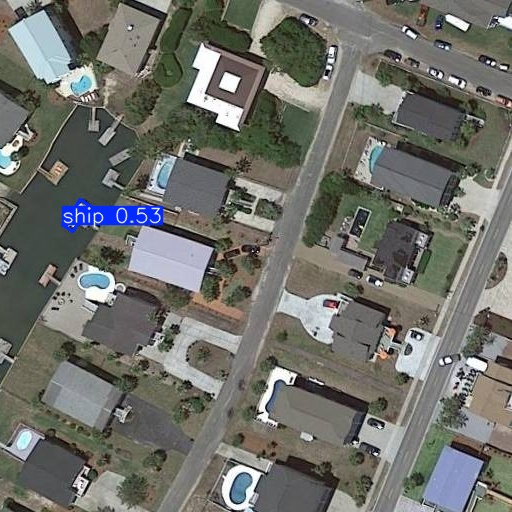

16267b285e7503740973e0f0f4c548a6_22_x2560_y1536.jpg


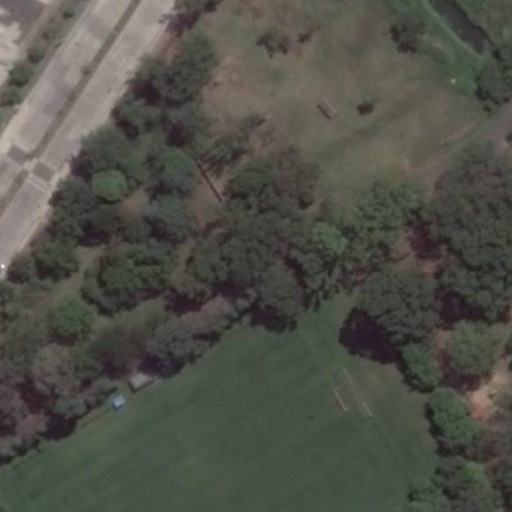

65913231e286b6eccfbc4472aa22b2ec_103_x1024_y2304.jpg


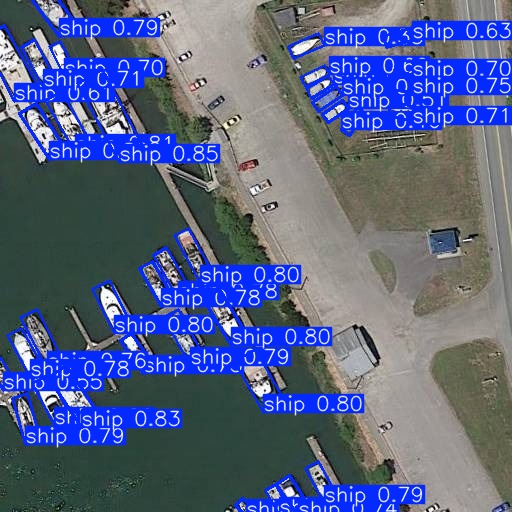

6785a335340e15fa3339d002094d447a_108_x256_y2048.jpg


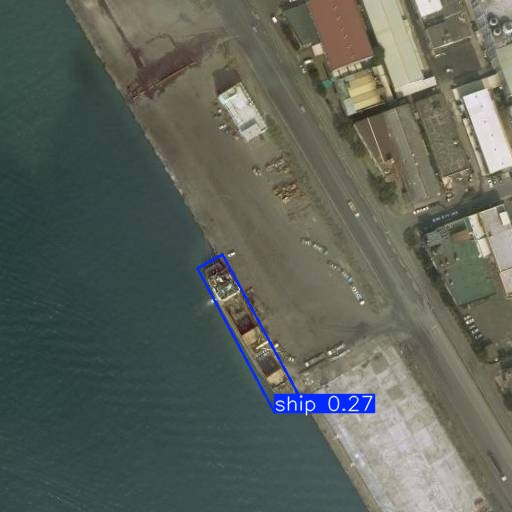

735ea21d97ff215c6556064ab652677b_120_x0_y1792.jpg


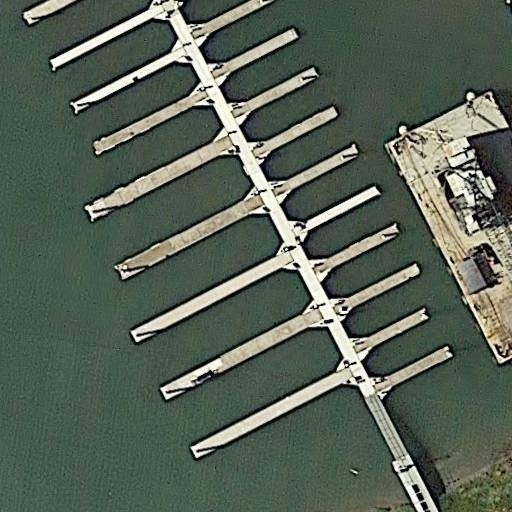

97f7c238a2d983d093ba421aa6e7b761_171_x3328_y2560.jpg


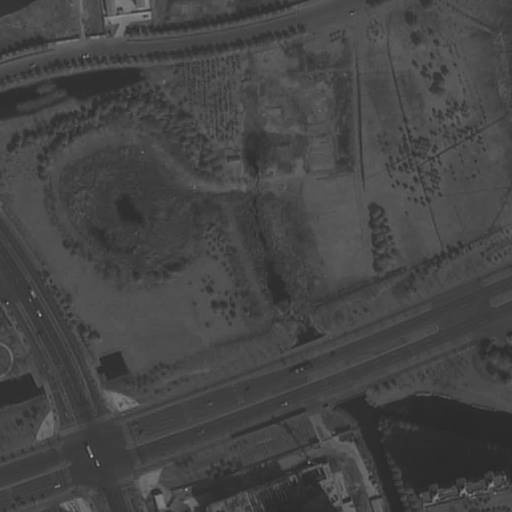

65913231e286b6eccfbc4472aa22b2ec_103_x1162_y1536.jpg


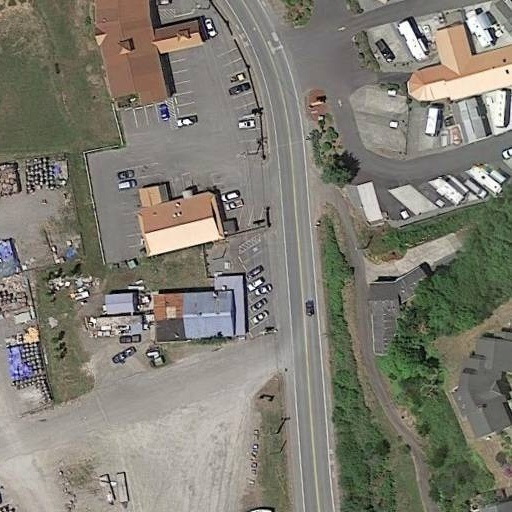

In [ ]:

import random
from pathlib import Path
from IPython.display import display, Image

# Folder containing the saved test predictions
prediction_dir = Path("/content/dota_v15_ship_results/test_predictions")

if not prediction_dir.exists():
    raise FileNotFoundError(f"Folder not found: {prediction_dir}")

# Find image files
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_files = [
    p for p in prediction_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
]

print(f"Annotated test images found: {len(image_files)}")

# Display up to 10 random images
for path in random.sample(image_files, min(10, len(image_files))):
    print(path.name)
    display(Image(filename=str(path)))


Annotated test images: 1998
8f8ad3c6d0781bb4479c18d234059d3e_158_x256_y256.jpg


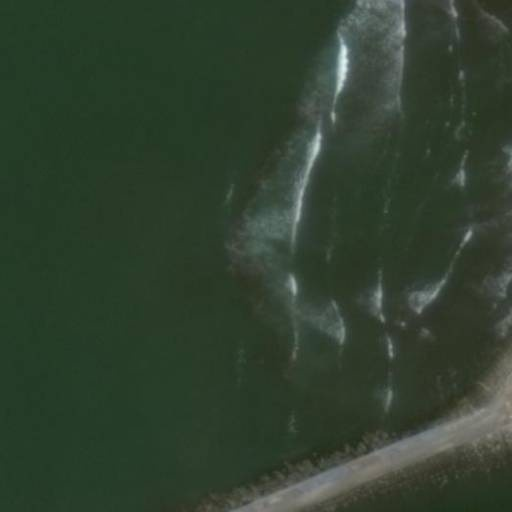

75e0835dd974a95acdb96cf5d8916827_125_x512_y768.jpg


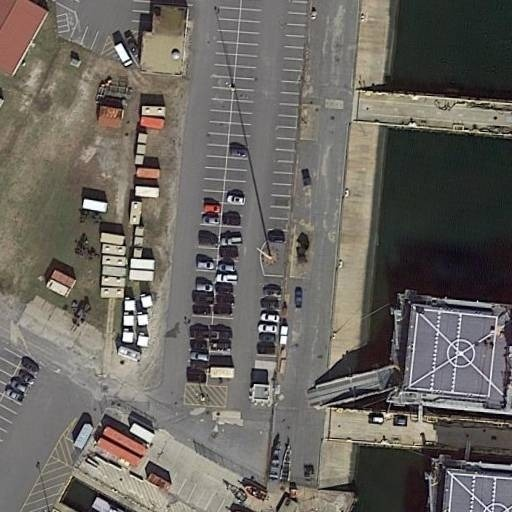

97f7c238a2d983d093ba421aa6e7b761_171_x256_y2560.jpg


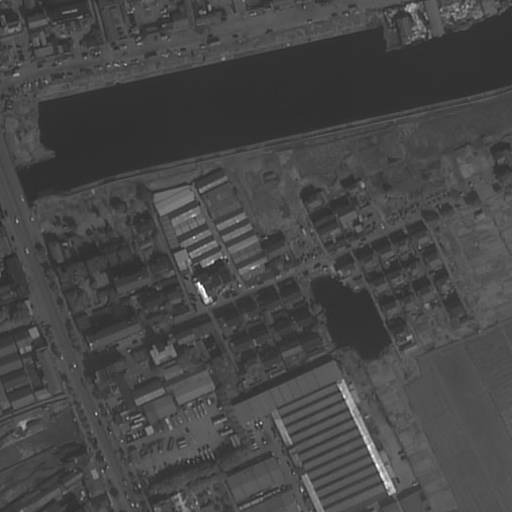

2ca6a35120c25b157cf6e045139f8fa7_46_x768_y768.jpg


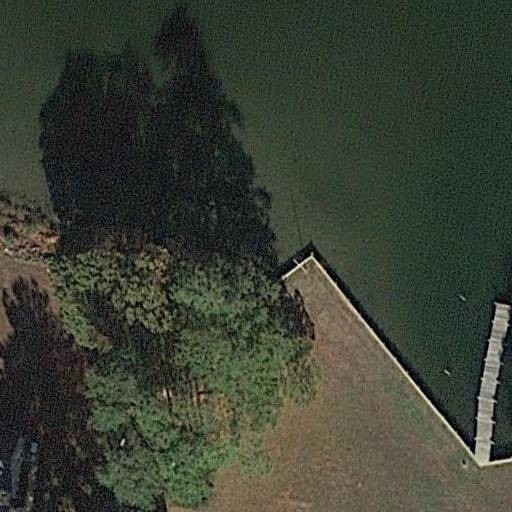

2079d402b79a8fc71f82ef151ed808b5_32_x768_y0.jpg


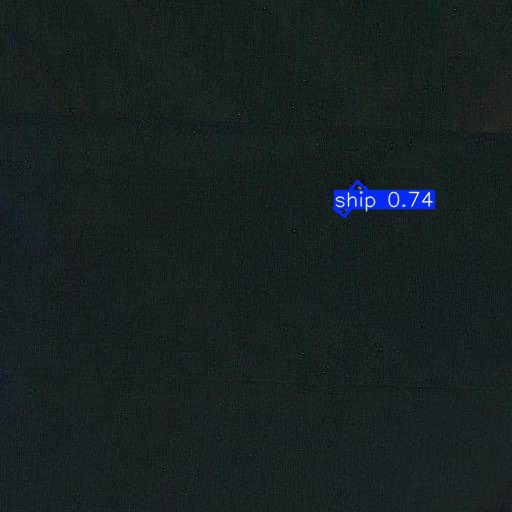

f6de8476ab83a984261e4427c1e02fb3_272_x768_y956.jpg


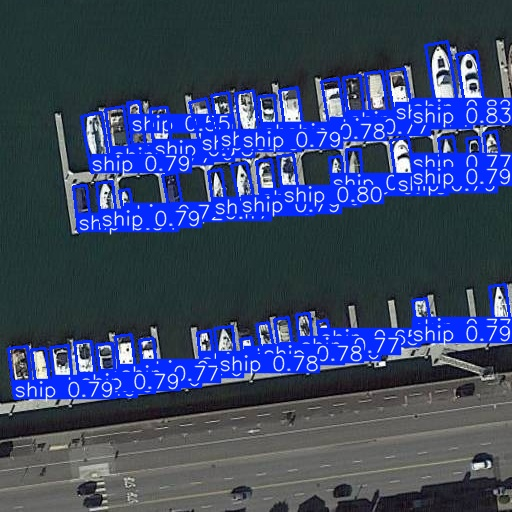

b126e774f1dbd18132a64ae9e63b5b93_202_x256_y1536.jpg


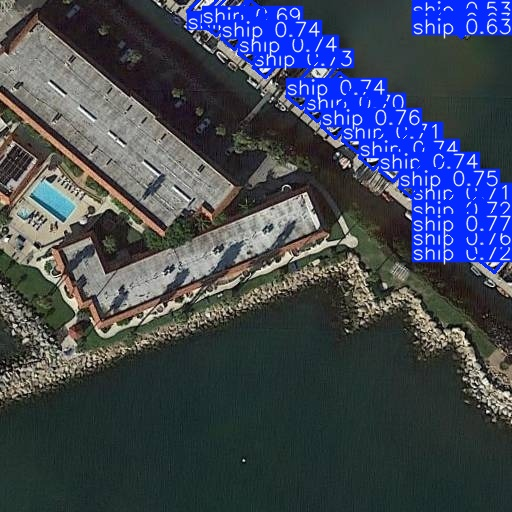

65913231e286b6eccfbc4472aa22b2ec_103_x1024_y512.jpg


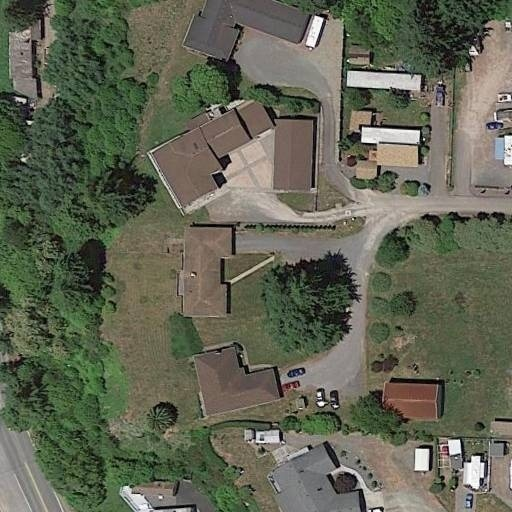

36e27c24a2b816d3270831adea988902_57_x768_y2304.jpg


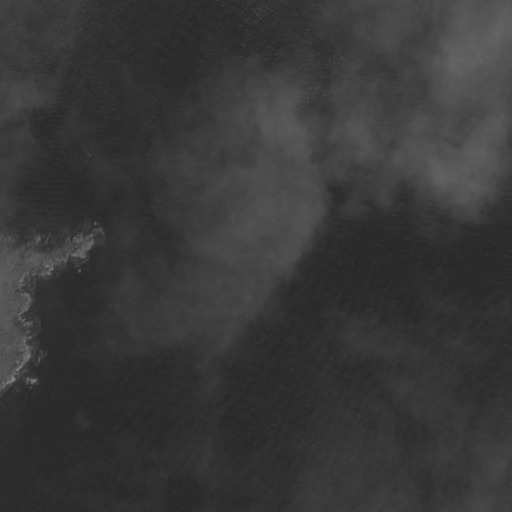

f6de8476ab83a984261e4427c1e02fb3_272_x1536_y956.jpg


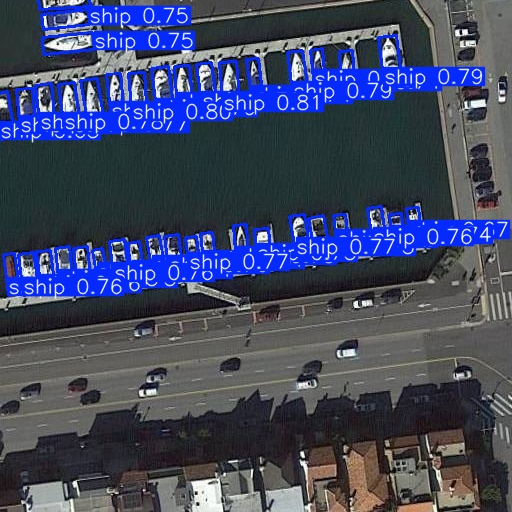

In [ ]:

import random
from pathlib import Path
from IPython.display import display, Image

prediction_dir = Path(
    "/content/dota_v15_ship_results/test_predictions"
)

if not prediction_dir.exists():
    print(f"Folder not found: {prediction_dir}")
else:
    image_files = [
        p for p in prediction_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [
            ".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"
        ]
    ]

    print(f"Annotated test images: {len(image_files)}")

    for path in random.sample(image_files, min(10, len(image_files))):
        print(path.name)
        display(Image(filename=str(path)))


In [ ]:
import json

evaluation_metrics = {
    "model": str(best_model_path),
    "image_size": 512,
    "validation": {
        "precision": float(val_results.box.mp),
        "recall": float(val_results.box.mr),
        "mAP50": float(val_results.box.map50),
        "mAP50_95": float(val_results.box.map)
    },
    "test": {
        "precision": float(test_results.box.mp),
        "recall": float(test_results.box.mr),
        "mAP50": float(test_results.box.map50),
        "mAP50_95": float(test_results.box.map)
    }
}

metrics_path = PROJECT_DIR / "evaluation_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(evaluation_metrics, f, indent=2)

print("Evaluation metrics saved to:", metrics_path)

Evaluation metrics saved to: /content/ship_detection/evaluation_metrics.json


test on an untiled image from the original dataset

In [ ]:

# ============================================================
# TEST YOLO11s-OBB ON ONE ORIGINAL UNTILED DOTA TEST IMAGE
# ============================================================

from pathlib import Path
from IPython.display import display
from PIL import Image
import random

# Original untiled test images
original_images_dir = Path("/content/dota_v15_ships/images/test")

# Find available images
image_files = sorted([
    p for p in original_images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
])

print("Original untiled test images:", len(image_files))

if not image_files:
    raise FileNotFoundError(
        f"No images found in {original_images_dir}. "
        "Check the original test dataset path."
    )

# Select one image at random
image_path = random.choice(image_files)

print("Testing image:", image_path.name)

# Run prediction on the original image
results = best_model.predict(
    source=str(image_path),
    imgsz=1024,
    conf=0.25,
    device=0,
    save=True,
    project=str(PROJECT_DIR),
    name="original_untiled_test",
    exist_ok=True
)

# Retrieve prediction results
result = results[0]

# Report detections
num_detections = len(result.obb) if result.obb is not None else 0

print("Ships detected:", num_detections)

if num_detections > 0:
    print(
        "Confidence scores:",
        result.obb.conf.cpu().numpy().round(3)
    )

# Display annotated original image
annotated_image = result.plot()
display(Image.fromarray(annotated_image[..., ::-1]))

# Report image dimensions and output location
print("Original image dimensions (height, width):", result.orig_shape)
print("Prediction output folder:", result.save_dir)


test on new imagery from- https://browser.moregeo.it/external/maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/events/tonga-volcano21/ard/acquisition_collections/10300100CCD4E100_collection.json

or

https://browser.moregeo.it/external/maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/events/tonga-volcano21/collection.json

prediction on new image without tiling technique

The yolo model does not work on planetdata because the imagery is that far away the ships just show up as white specks- this is a limitation of this process

Create and download results zip

In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

zip_path = Path("/content/dota_v15_ship_results.zip")

folders_to_save = [
    RUN_DIR,                                  # Training logs, plots, weights
    PROJECT_DIR / "validation",               # Validation outputs
    PROJECT_DIR / "test",                     # Test evaluation outputs
    PROJECT_DIR / "test_predictions",         # Annotated test tiles
    PROJECT_DIR / "original_untiled_test",    # Original-image predictions
    PROJECT_DIR / "new_image_predictions"     # Predictions on uploaded images
]

files_to_save = [
    PROJECT_DIR / "evaluation_metrics.json",
    PROJECT_DIR / "metrics_comparison.csv"
]

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:

    for folder in folders_to_save:
        if folder.exists():
            for file_path in folder.rglob("*"):
                if file_path.is_file():
                    archive.write(
                        file_path,
                        arcname=str(file_path.relative_to(PROJECT_DIR))
                    )

    for file_path in files_to_save:
        if file_path.exists():
            archive.write(
                file_path,
                arcname=file_path.name
            )

print("ZIP created:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024**2), 2))

files.download(str(zip_path))


ZIP created: /content/dota_v15_ship_results.zip
ZIP size (MB): 313.15


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>